In [1]:
# ============================================================
# DEMARCHE_ENCAD3 — CASE STUDY 3 : BEIJING AIR QUALITY
# ETAPE 1 — CONSTRUCTION TRACABLE DE Dataset_REF
# ============================================================

from pathlib import Path
import pandas as pd
import hashlib
import json
from datetime import datetime

# ------------------------------------------------------------
# 1. CHEMINS DU PROJET
# ------------------------------------------------------------

PROJECT_ROOT = Path(
    r"C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3\CASE_STUDY_3_BEIJING"
)

RAW_DIR = PROJECT_ROOT / "data" / "raw"
REF_DIR = PROJECT_ROOT / "data" / "reference"
RESULT_DIR = PROJECT_ROOT / "results" / "01_reference"

REF_DIR.mkdir(parents=True, exist_ok=True)
RESULT_DIR.mkdir(parents=True, exist_ok=True)

DATASET_REF_PATH = REF_DIR / "Dataset_REF.csv"
METADATA_PATH = RESULT_DIR / "step01_dataset_ref_metadata.json"
SOURCE_MANIFEST_PATH = RESULT_DIR / "step01_source_manifest.csv"


# ------------------------------------------------------------
# 2. FONCTION SHA-256
# ------------------------------------------------------------

def sha256_file(path, chunk_size=1024 * 1024):
    h = hashlib.sha256()

    with open(path, "rb") as f:
        while True:
            chunk = f.read(chunk_size)

            if not chunk:
                break

            h.update(chunk)

    return h.hexdigest()


# ------------------------------------------------------------
# 3. RECHERCHE DES CSV ORIGINAUX
# ------------------------------------------------------------

csv_files = sorted(RAW_DIR.rglob("PRSA_Data_*.csv"))

print("=" * 80)
print("ETAPE 1 — CONSTRUCTION DE Dataset_REF")
print("=" * 80)

print(f"\nRépertoire RAW : {RAW_DIR}")
print(f"Nombre de fichiers PRSA trouvés : {len(csv_files)}")

if len(csv_files) != 12:
    raise ValueError(
        f"ERREUR : 12 fichiers PRSA étaient attendus, "
        f"mais {len(csv_files)} ont été trouvés."
    )

print("\nFichiers détectés :")

for i, file in enumerate(csv_files, start=1):
    print(f"{i:02d}. {file.name}")


# ------------------------------------------------------------
# 4. LECTURE + CONTROLE INDIVIDUEL DES 12 FICHIERS
# ------------------------------------------------------------

datasets = []
manifest = []
reference_columns = None

for file in csv_files:

    df = pd.read_csv(
        file,
        na_values=["NA"],
        keep_default_na=True
    )

    # --------------------------------------------------------
    # Vérification de la structure
    # --------------------------------------------------------

    if reference_columns is None:
        reference_columns = list(df.columns)

    elif list(df.columns) != reference_columns:
        raise ValueError(
            f"Structure incompatible détectée dans : {file.name}\n"
            f"Colonnes attendues : {reference_columns}\n"
            f"Colonnes trouvées  : {list(df.columns)}"
        )

    # --------------------------------------------------------
    # Vérification présence colonne station
    # --------------------------------------------------------

    if "station" not in df.columns:
        raise ValueError(
            f"La colonne 'station' est absente de {file.name}"
        )

    stations = df["station"].dropna().unique()

    if len(stations) != 1:
        raise ValueError(
            f"{file.name} contient {len(stations)} stations : {stations}"
        )

    station = str(stations[0])

    # --------------------------------------------------------
    # Empreinte du fichier source
    # --------------------------------------------------------

    source_sha256 = sha256_file(file)

    # --------------------------------------------------------
    # Manifest
    # --------------------------------------------------------

    manifest.append({
        "source_file": file.name,
        "station": station,
        "n_rows": len(df),
        "n_columns": len(df.columns),
        "missing_cells": int(df.isna().sum().sum()),
        "sha256": source_sha256
    })

    datasets.append(df)


# ------------------------------------------------------------
# 5. MANIFEST DES SOURCES
# ------------------------------------------------------------

manifest_df = pd.DataFrame(manifest)

print("\n" + "=" * 80)
print("CONTROLE DES FICHIERS SOURCES")
print("=" * 80)

print(
    manifest_df[
        ["source_file", "station", "n_rows",
         "n_columns", "missing_cells"]
    ].to_string(index=False)
)

print("\nNombre de stations distinctes :",
      manifest_df["station"].nunique())

print("Nombre total de lignes avant concaténation :",
      manifest_df["n_rows"].sum())


# ------------------------------------------------------------
# 6. CONCATENATION
# ------------------------------------------------------------

dataset_ref = pd.concat(
    datasets,
    axis=0,
    ignore_index=True
)

print("\n" + "=" * 80)
print("DATASET CONSOLIDE")
print("=" * 80)

print("Dimensions :", dataset_ref.shape)


# ------------------------------------------------------------
# 7. CONSTRUCTION D'UN TIMESTAMP
# ------------------------------------------------------------
# IMPORTANT :
# Les colonnes year/month/day/hour originales sont conservées.
# timestamp est uniquement ajouté pour faciliter les analyses
# temporelles futures.

required_time_columns = ["year", "month", "day", "hour"]

missing_time_columns = [
    c for c in required_time_columns
    if c not in dataset_ref.columns
]

if missing_time_columns:
    raise ValueError(
        f"Colonnes temporelles absentes : {missing_time_columns}"
    )

dataset_ref["timestamp"] = pd.to_datetime(
    dataset_ref[["year", "month", "day", "hour"]]
)

# ------------------------------------------------------------
# 8. CONTROLES TEMPORELS
# ------------------------------------------------------------

date_min = dataset_ref["timestamp"].min()
date_max = dataset_ref["timestamp"].max()

duplicate_station_time = int(
    dataset_ref.duplicated(
        subset=["station", "timestamp"]
    ).sum()
)

print("\nPériode détectée :")
print("Début :", date_min)
print("Fin   :", date_max)

print("\nDoublons station × timestamp :",
      duplicate_station_time)


# ------------------------------------------------------------
# 9. CONTROLE DES STATIONS
# ------------------------------------------------------------

station_counts = (
    dataset_ref
    .groupby("station")
    .size()
    .sort_index()
)

print("\nNombre d'observations par station :")
print(station_counts.to_string())


# ------------------------------------------------------------
# 10. CONTROLE DES COLONNES
# ------------------------------------------------------------

print("\nColonnes Dataset_REF :")

for i, col in enumerate(dataset_ref.columns, start=1):
    print(f"{i:02d}. {col}")


# ------------------------------------------------------------
# 11. INFORMATION SUR LES VALEURS MANQUANTES
# ------------------------------------------------------------
# ATTENTION :
# Ceci est seulement un comptage descriptif.
# Aucune interprétation et aucune correction.

missing_summary = (
    dataset_ref
    .isna()
    .sum()
    .sort_values(ascending=False)
)

print("\nValeurs manquantes par variable :")

print(
    missing_summary[
        missing_summary > 0
    ].to_string()
)


# ------------------------------------------------------------
# 12. TRI DETERMINISTE
# ------------------------------------------------------------
# Garantit que Dataset_REF possède un ordre reproductible.

dataset_ref = (
    dataset_ref
    .sort_values(["timestamp", "station"])
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 13. SAUVEGARDE DU MANIFEST
# ------------------------------------------------------------

manifest_df.to_csv(
    SOURCE_MANIFEST_PATH,
    index=False,
    encoding="utf-8"
)


# ------------------------------------------------------------
# 14. CREATION OFFICIELLE DE Dataset_REF
# ------------------------------------------------------------

dataset_ref.to_csv(
    DATASET_REF_PATH,
    index=False,
    encoding="utf-8",
    na_rep="NA"
)


# ------------------------------------------------------------
# 15. SHA-256 DE Dataset_REF
# ------------------------------------------------------------

dataset_ref_sha256 = sha256_file(DATASET_REF_PATH)


# ------------------------------------------------------------
# 16. METADONNEES DE TRACABILITE
# ------------------------------------------------------------

metadata = {

    "experiment": "DEMARCHE_ENCAD3_CASE_STUDY_3",

    "step": "01_CONSTRUCTION_DATASET_REF",

    "creation_time": datetime.now().isoformat(),

    "source": {
        "dataset_name": "Beijing Multi-Site Air Quality",
        "repository": "UCI Machine Learning Repository",
        "doi": "10.24432/C5RK5G",
        "number_source_files": len(csv_files)
    },

    "dataset_ref": {
        "path": str(DATASET_REF_PATH),
        "rows": int(dataset_ref.shape[0]),
        "columns": int(dataset_ref.shape[1]),
        "stations": int(dataset_ref["station"].nunique()),
        "date_min": str(date_min),
        "date_max": str(date_max),
        "duplicate_station_timestamp": duplicate_station_time,
        "sha256": dataset_ref_sha256
    },

    "transformation": {
        "source_files_concatenated": True,
        "timestamp_added": True,
        "rows_deleted": 0,
        "missing_values_imputed": False,
        "outliers_modified": False,
        "measurements_corrected": False
    },

    "source_files": manifest
}

with open(
    METADATA_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metadata,
        f,
        indent=4,
        ensure_ascii=False
    )


# ------------------------------------------------------------
# 17. CONTROLES FINAUX
# ------------------------------------------------------------

expected_rows = 420_768
expected_stations = 12

print("\n" + "=" * 80)
print("CONTROLE FINAL")
print("=" * 80)

print(f"Lignes obtenues     : {len(dataset_ref):,}")
print(f"Lignes UCI attendues: {expected_rows:,}")

print(
    "Contrôle lignes     :",
    "OK" if len(dataset_ref) == expected_rows
    else "A VERIFIER"
)

print(f"\nStations obtenues   : {dataset_ref['station'].nunique()}")
print(f"Stations attendues  : {expected_stations}")

print(
    "Contrôle stations   :",
    "OK"
    if dataset_ref["station"].nunique() == expected_stations
    else "A VERIFIER"
)

print(
    "\nDoublons station × timestamp :",
    duplicate_station_time
)

print("\nSHA-256 Dataset_REF :")
print(dataset_ref_sha256)

print("\nFichiers créés :")
print("1.", DATASET_REF_PATH)
print("2.", SOURCE_MANIFEST_PATH)
print("3.", METADATA_PATH)

print("\n" + "=" * 80)
print("Dataset_REF CREE AVEC SUCCES")
print("AUCUNE CORRECTION DE DONNEES N'A ETE EFFECTUEE.")
print("=" * 80)

ETAPE 1 — CONSTRUCTION DE Dataset_REF

Répertoire RAW : C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3\CASE_STUDY_3_BEIJING\data\raw
Nombre de fichiers PRSA trouvés : 12

Fichiers détectés :
01. PRSA_Data_Aotizhongxin_20130301-20170228.csv
02. PRSA_Data_Changping_20130301-20170228.csv
03. PRSA_Data_Dingling_20130301-20170228.csv
04. PRSA_Data_Dongsi_20130301-20170228.csv
05. PRSA_Data_Guanyuan_20130301-20170228.csv
06. PRSA_Data_Gucheng_20130301-20170228.csv
07. PRSA_Data_Huairou_20130301-20170228.csv
08. PRSA_Data_Nongzhanguan_20130301-20170228.csv
09. PRSA_Data_Shunyi_20130301-20170228.csv
10. PRSA_Data_Tiantan_20130301-20170228.csv
11. PRSA_Data_Wanliu_20130301-20170228.csv
12. PRSA_Data_Wanshouxigong_20130301-20170228.csv

CONTROLE DES FICHIERS SOURCES
                                  source_file       station  n_rows  n_columns  missing_cells
 PRSA_Data_Aotizhongxin_20130301-20170228.csv  Aotizhongxin   35064         18           7271
    PRSA_Data_Changping_2013

In [2]:
# ============================================================
# DEMARCHE_ENCAD3 - CASE STUDY 3
# STEP 02 - CONSTRUCTION OF MODELING_VIEW_REF
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import hashlib
import json
from datetime import datetime

# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------

ROOT = Path(
    r"C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3\CASE_STUDY_3_BEIJING"
)

DATASET_REF_PATH = ROOT / "data" / "reference" / "Dataset_REF.csv"
OUTPUT_DIR = ROOT / "results" / "01_reference"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MODELING_VIEW_PATH = OUTPUT_DIR / "step02_modeling_view_ref.csv"
METADATA_PATH = OUTPUT_DIR / "step02_modeling_view_ref_metadata.json"
SPLIT_SUMMARY_PATH = OUTPUT_DIR / "step02_modeling_view_ref_split_summary.csv"
MISSING_SUMMARY_PATH = OUTPUT_DIR / "step02_modeling_view_ref_missing_summary.csv"


# ------------------------------------------------------------
# 2. FIXED PROTOCOL
# ------------------------------------------------------------

EXPECTED_DATASET_REF_SHA256 = (
    "60286d59f5a7c22290e527bf0381b56ddee9223f4f93f856fb6f08912406278f"
)

TARGET_SOURCE = "PM2.5"
TARGET_NAME = "target_PM25_t_plus_1"
HORIZON_HOURS = 1

TRAIN_START = pd.Timestamp("2013-03-01 00:00:00")
TRAIN_END = pd.Timestamp("2015-02-28 23:59:59")

VALIDATION_START = pd.Timestamp("2015-03-01 00:00:00")
VALIDATION_END = pd.Timestamp("2016-02-29 23:59:59")

TEST_START = pd.Timestamp("2016-03-01 00:00:00")
TEST_END = pd.Timestamp("2017-02-28 23:59:59")

X_MODEL = [
    "PM2.5",
    "PM10",
    "SO2",
    "NO2",
    "CO",
    "O3",
    "TEMP",
    "PRES",
    "DEWP",
    "RAIN",
    "WSPM",
    "wd",
    "station",
    "hour",
    "month"
]

EXCLUDED_FROM_X = [
    "No",
    "year",
    "day",
    "timestamp"
]


# ------------------------------------------------------------
# 3. UTILITY
# ------------------------------------------------------------

def sha256_file(path, chunk_size=1024 * 1024):
    h = hashlib.sha256()

    with open(path, "rb") as f:
        while True:
            chunk = f.read(chunk_size)

            if not chunk:
                break

            h.update(chunk)

    return h.hexdigest()


# ------------------------------------------------------------
# 4. VERIFY DATASET_REF BEFORE PROCESSING
# ------------------------------------------------------------

actual_sha256 = sha256_file(DATASET_REF_PATH)

if actual_sha256 != EXPECTED_DATASET_REF_SHA256:
    raise RuntimeError(
        "\nDATASET_REF SHA-256 MISMATCH.\n"
        f"Expected : {EXPECTED_DATASET_REF_SHA256}\n"
        f"Actual   : {actual_sha256}\n"
        "STEP 02 STOPPED."
    )

print("Dataset_REF SHA-256 verification : PASS")


# ------------------------------------------------------------
# 5. LOAD DATASET_REF
# ------------------------------------------------------------

df_ref = pd.read_csv(DATASET_REF_PATH)

required_columns = [
    "No",
    "year",
    "month",
    "day",
    "hour",
    "PM2.5",
    "PM10",
    "SO2",
    "NO2",
    "CO",
    "O3",
    "TEMP",
    "PRES",
    "DEWP",
    "RAIN",
    "wd",
    "WSPM",
    "station",
    "timestamp"
]

missing_columns = [
    col for col in required_columns
    if col not in df_ref.columns
]

if missing_columns:
    raise RuntimeError(
        f"Missing required columns: {missing_columns}"
    )

df_ref["timestamp"] = pd.to_datetime(
    df_ref["timestamp"],
    errors="raise"
)

n_rows_ref = len(df_ref)
n_stations = df_ref["station"].nunique()

duplicate_station_timestamp = int(
    df_ref.duplicated(
        subset=["station", "timestamp"]
    ).sum()
)

if duplicate_station_timestamp != 0:
    raise RuntimeError(
        "Duplicate station × timestamp detected. "
        "STEP 02 STOPPED."
    )


# ------------------------------------------------------------
# 6. CREATE WORKING COPY
# Dataset_REF itself is NEVER modified
# ------------------------------------------------------------

df = (
    df_ref
    .copy()
    .sort_values(["station", "timestamp"])
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 7. BUILD t -> t+1 RELATION WITHIN EACH STATION
# ------------------------------------------------------------

df["target_timestamp"] = (
    df.groupby("station")["timestamp"].shift(-1)
)

df[TARGET_NAME] = (
    df.groupby("station")[TARGET_SOURCE].shift(-1)
)

df["target_station"] = (
    df.groupby("station")["station"].shift(-1)
)

df["delta_hours_to_target"] = (
    (df["target_timestamp"] - df["timestamp"])
    .dt.total_seconds()
    .div(3600)
)

df["is_exact_t_plus_1"] = (
    df["delta_hours_to_target"] == HORIZON_HOURS
)


# ------------------------------------------------------------
# 8. STRICT TEMPORAL VALIDITY CHECK
# ------------------------------------------------------------

station_mismatch = (
    df["target_station"].notna()
    &
    (df["station"] != df["target_station"])
)

if station_mismatch.any():
    raise RuntimeError(
        "Cross-station target construction detected. "
        "STEP 02 STOPPED."
    )

non_consecutive_mask = (
    df["target_timestamp"].notna()
    &
    (~df["is_exact_t_plus_1"])
)

n_non_consecutive = int(non_consecutive_mask.sum())


# ------------------------------------------------------------
# 9. SUPERVISED ELIGIBILITY
#
# No row is deleted here.
# We only identify whether the row can participate
# in supervised learning for PM2.5(t+1).
# ------------------------------------------------------------

df["eligible_supervised"] = (
    df["is_exact_t_plus_1"]
    &
    df[TARGET_NAME].notna()
)


# ------------------------------------------------------------
# 10. TEMPORAL SPLIT
# Split is determined by TARGET timestamp.
# ------------------------------------------------------------

df["split"] = "NOT_ELIGIBLE"

eligible = df["eligible_supervised"]

train_mask = (
    eligible
    &
    df["target_timestamp"].between(
        TRAIN_START,
        TRAIN_END
    )
)

validation_mask = (
    eligible
    &
    df["target_timestamp"].between(
        VALIDATION_START,
        VALIDATION_END
    )
)

test_mask = (
    eligible
    &
    df["target_timestamp"].between(
        TEST_START,
        TEST_END
    )
)

df.loc[train_mask, "split"] = "TRAIN"
df.loc[validation_mask, "split"] = "VALIDATION"
df.loc[test_mask, "split"] = "TEST"


# ------------------------------------------------------------
# 11. CHECK THAT ALL ELIGIBLE ROWS RECEIVED A SPLIT
# ------------------------------------------------------------

eligible_without_split = int(
    (
        df["eligible_supervised"]
        &
        (df["split"] == "NOT_ELIGIBLE")
    ).sum()
)

if eligible_without_split != 0:
    raise RuntimeError(
        f"{eligible_without_split} eligible rows "
        "did not receive TRAIN/VALIDATION/TEST. "
        "STEP 02 STOPPED."
    )


# ------------------------------------------------------------
# 12. MISSINGNESS SUMMARY OF X_MODEL
#
# IMPORTANT:
# Missing values are counted only.
# No imputation.
# ------------------------------------------------------------

missing_summary = pd.DataFrame({
    "feature": X_MODEL,
    "missing_count_dataset_ref": [
        int(df[col].isna().sum())
        for col in X_MODEL
    ],
    "missing_percent_dataset_ref": [
        float(df[col].isna().mean() * 100)
        for col in X_MODEL
    ]
})

missing_summary["missing_count_train"] = [
    int(df.loc[df["split"] == "TRAIN", col].isna().sum())
    for col in X_MODEL
]

missing_summary["missing_count_validation"] = [
    int(df.loc[df["split"] == "VALIDATION", col].isna().sum())
    for col in X_MODEL
]

missing_summary["missing_count_test"] = [
    int(df.loc[df["split"] == "TEST", col].isna().sum())
    for col in X_MODEL
]


# ------------------------------------------------------------
# 13. SPLIT SUMMARY
# ------------------------------------------------------------

split_summary = (
    df["split"]
    .value_counts(dropna=False)
    .rename_axis("split")
    .reset_index(name="rows")
)

split_summary["percent_of_dataset_ref"] = (
    split_summary["rows"]
    / len(df)
    * 100
)


# ------------------------------------------------------------
# 14. TRACEABILITY METADATA
# ------------------------------------------------------------

n_valid_transitions = int(
    df["is_exact_t_plus_1"].sum()
)

n_missing_target = int(
    (
        df["is_exact_t_plus_1"]
        &
        df[TARGET_NAME].isna()
    ).sum()
)

n_eligible = int(
    df["eligible_supervised"].sum()
)

metadata = {

    "experiment":
        "DEMARCHE_ENCAD3_CASE_STUDY_3",

    "step":
        "02_CONSTRUCTION_MODELING_VIEW_REF",

    "creation_time":
        datetime.now().isoformat(),

    "dataset_ref": {
        "path": str(DATASET_REF_PATH),
        "sha256_expected":
            EXPECTED_DATASET_REF_SHA256,
        "sha256_actual":
            actual_sha256,
        "sha256_verified": True,
        "rows": int(n_rows_ref),
        "stations": int(n_stations),
        "duplicate_station_timestamp":
            duplicate_station_timestamp
    },

    "prediction_task": {
        "target":
            "PM2.5(t+1)",
        "target_column":
            TARGET_NAME,
        "forecast_horizon_hours":
            HORIZON_HOURS,
        "same_station_target":
            True
    },

    "x_model": X_MODEL,

    "excluded_from_x":
        EXCLUDED_FROM_X,

    "temporal_protocol": {
        "split_basis":
            "target_timestamp",
        "train":
            "2013-03-01 to 2015-02-28",
        "validation":
            "2015-03-01 to 2016-02-29",
        "test":
            "2016-03-01 to 2017-02-28"
    },

    "transition_audit": {
        "valid_exact_t_plus_1":
            n_valid_transitions,
        "non_consecutive_transitions":
            n_non_consecutive,
        "missing_target_pm25":
            n_missing_target,
        "eligible_supervised_rows":
            n_eligible
    },

    "data_quality_preservation": {
        "dataset_ref_modified":
            False,
        "predictor_imputation":
            False,
        "outliers_modified":
            False,
        "measurements_corrected":
            False,
        "rows_deleted_from_dataset_ref":
            0
    }
}


# ------------------------------------------------------------
# 15. SAVE ARTIFACTS
# ------------------------------------------------------------

df.to_csv(
    MODELING_VIEW_PATH,
    index=False
)

split_summary.to_csv(
    SPLIT_SUMMARY_PATH,
    index=False
)

missing_summary.to_csv(
    MISSING_SUMMARY_PATH,
    index=False
)

with open(
    METADATA_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metadata,
        f,
        indent=4,
        ensure_ascii=False
    )


# ------------------------------------------------------------
# 16. SHA-256 OF GENERATED MODELING VIEW
# ------------------------------------------------------------

modeling_view_sha256 = sha256_file(
    MODELING_VIEW_PATH
)

metadata["modeling_view_ref"] = {
    "path":
        str(MODELING_VIEW_PATH),
    "rows":
        int(len(df)),
    "sha256":
        modeling_view_sha256
}

with open(
    METADATA_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metadata,
        f,
        indent=4,
        ensure_ascii=False
    )


# ------------------------------------------------------------
# 17. FINAL REPORT
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("STEP 02 - MODELING_VIEW_REF")
print("=" * 70)

print(
    f"\nRows Dataset_REF                 : {n_rows_ref:,}"
)

print(
    f"Stations                         : {n_stations}"
)

print(
    "Duplicate station × timestamp    : "
    f"{duplicate_station_timestamp}"
)

print(
    f"\nValid exact t -> t+1 transitions : "
    f"{n_valid_transitions:,}"
)

print(
    f"Non-consecutive transitions      : "
    f"{n_non_consecutive:,}"
)

print(
    f"Missing PM2.5(t+1) targets       : "
    f"{n_missing_target:,}"
)

print(
    f"Eligible supervised rows         : "
    f"{n_eligible:,}"
)

print("\nSplit summary:")
print(split_summary.to_string(index=False))

print("\nMissingness in X_MODEL:")
print(missing_summary.to_string(index=False))

print(
    "\nPredictor NaNs imputed           : 0"
)

print(
    "Outliers modified                : 0"
)

print(
    "Measurements corrected           : 0"
)

print(
    "Rows deleted from Dataset_REF    : 0"
)

print(
    f"\nModeling_View_REF SHA-256        : "
    f"{modeling_view_sha256}"
)

print("\nArtifacts created:")

print(
    f" - {MODELING_VIEW_PATH}"
)

print(
    f" - {METADATA_PATH}"
)

print(
    f" - {SPLIT_SUMMARY_PATH}"
)

print(
    f" - {MISSING_SUMMARY_PATH}"
)

print("\nSTEP 02 COMPLETED.")

Dataset_REF SHA-256 verification : PASS

STEP 02 - MODELING_VIEW_REF

Rows Dataset_REF                 : 420,768
Stations                         : 12
Duplicate station × timestamp    : 0

Valid exact t -> t+1 transitions : 420,756
Non-consecutive transitions      : 0
Missing PM2.5(t+1) targets       : 8,739
Eligible supervised rows         : 412,017

Split summary:
       split   rows  percent_of_dataset_ref
       TRAIN 205977               48.952629
  VALIDATION 103287               24.547256
        TEST 102753               24.420346
NOT_ELIGIBLE   8751                2.079768

Missingness in X_MODEL:
feature  missing_count_dataset_ref  missing_percent_dataset_ref  missing_count_train  missing_count_validation  missing_count_test
  PM2.5                       8739                     2.076916                 1112                       808                 917
   PM10                       6449                     1.532674                  909                       562              

In [5]:
pip install catboost

   ---------------------------------------- 0.0/100.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/100.2 MB ? eta -:--:--
   ---------------------------------------- 0.3/100.2 MB ? eta -:--:--
   ---------------------------------------- 0.5/100.2 MB 1.4 MB/s eta 0:01:12
   ---------------------------------------- 0.8/100.2 MB 1.5 MB/s eta 0:01:08
   ---------------------------------------- 1.0/100.2 MB 1.4 MB/s eta 0:01:09
    --------------------------------------- 1.6/100.2 MB 1.4 MB/s eta 0:01:10
    --------------------------------------- 1.8/100.2 MB 1.5 MB/s eta 0:01:07
    --------------------------------------- 2.1/100.2 MB 1.5 MB/s eta 0:01:07
    --------------------------------------- 2.4/100.2 MB 1.5 MB/s eta 0:01:07
   - -------------------------------------- 2.6/100.2 MB 1.5 MB/s eta 0:01:08
   - -------------------------------------- 3.1/100.2 MB 1.5 MB/s eta 0:01:06
   - -------------------------------------- 3.4/100.2 MB 1.5 MB/s eta 0:01:07
   - --

In [1]:
# ============================================================
# DEMARCHE_ENCAD3 - CASE STUDY 3
# STEP 03 - TRAINING AND EVALUATION OF MODEL_REF
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import hashlib
import json
import pickle
from datetime import datetime

from catboost import CatBoostRegressor
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------

ROOT = Path(
    r"C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3\CASE_STUDY_3_BEIJING"
)

MODELING_VIEW_PATH = (
    ROOT / "results" / "01_reference" /
    "step02_modeling_view_ref.csv"
)

MODEL_DIR = ROOT / "models"
RESULT_DIR = ROOT / "results" / "01_reference"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
RESULT_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = MODEL_DIR / "Model_REF.cbm"

METRICS_PATH = (
    RESULT_DIR / "step03_model_ref_metrics.csv"
)

PREDICTIONS_PATH = (
    RESULT_DIR / "step03_model_ref_predictions.csv"
)

METADATA_PATH = (
    RESULT_DIR / "step03_model_ref_metadata.json"
)


# ------------------------------------------------------------
# 2. FIXED INPUT SHA-256
# ------------------------------------------------------------

EXPECTED_MODELING_VIEW_SHA256 = (
    "a0f2090baf731f1064d4be63769c3e62"
    "bf875a517eb1389de9518e18893f20cb"
)


def sha256_file(path, chunk_size=1024 * 1024):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        while True:

            chunk = f.read(chunk_size)

            if not chunk:
                break

            h.update(chunk)

    return h.hexdigest()


actual_sha256 = sha256_file(
    MODELING_VIEW_PATH
)

if actual_sha256 != EXPECTED_MODELING_VIEW_SHA256:

    raise RuntimeError(
        "\nModeling_View_REF SHA-256 mismatch.\n"
        f"Expected : {EXPECTED_MODELING_VIEW_SHA256}\n"
        f"Actual   : {actual_sha256}\n"
        "STEP 03 STOPPED."
    )

print("Modeling_View_REF SHA-256 verification : PASS")


# ------------------------------------------------------------
# 3. FIXED PREDICTION PROTOCOL
# ------------------------------------------------------------

TARGET = "target_PM25_t_plus_1"

X_MODEL = [
    "PM2.5",
    "PM10",
    "SO2",
    "NO2",
    "CO",
    "O3",
    "TEMP",
    "PRES",
    "DEWP",
    "RAIN",
    "WSPM",
    "wd",
    "station",
    "hour",
    "month"
]

CATEGORICAL_FEATURES = [
    "wd",
    "station"
]

RANDOM_SEED = 42


# ------------------------------------------------------------
# 4. LOAD MODELING VIEW
# ------------------------------------------------------------

df = pd.read_csv(
    MODELING_VIEW_PATH,
    low_memory=False
)

df["timestamp"] = pd.to_datetime(
    df["timestamp"],
    errors="raise"
)

df["target_timestamp"] = pd.to_datetime(
    df["target_timestamp"],
    errors="coerce"
)


# ------------------------------------------------------------
# 5. VERIFY SUPERVISED PARTITIONS
# ------------------------------------------------------------

train_df = (
    df.loc[df["split"] == "TRAIN"]
    .copy()
)

validation_df = (
    df.loc[df["split"] == "VALIDATION"]
    .copy()
)

test_df = (
    df.loc[df["split"] == "TEST"]
    .copy()
)

EXPECTED_COUNTS = {
    "TRAIN": 205977,
    "VALIDATION": 103287,
    "TEST": 102753
}

actual_counts = {
    "TRAIN": len(train_df),
    "VALIDATION": len(validation_df),
    "TEST": len(test_df)
}

if actual_counts != EXPECTED_COUNTS:

    raise RuntimeError(
        "Unexpected split sizes.\n"
        f"Expected: {EXPECTED_COUNTS}\n"
        f"Actual:   {actual_counts}"
    )

for name, part in [
    ("TRAIN", train_df),
    ("VALIDATION", validation_df),
    ("TEST", test_df)
]:

    if part[TARGET].isna().any():

        raise RuntimeError(
            f"{name} contains missing target values."
        )


# ------------------------------------------------------------
# 6. CREATE X / y
# ------------------------------------------------------------

X_train = train_df[X_MODEL].copy()
X_validation = validation_df[X_MODEL].copy()
X_test = test_df[X_MODEL].copy()

y_train = train_df[TARGET].copy()
y_validation = validation_df[TARGET].copy()
y_test = test_df[TARGET].copy()


# ------------------------------------------------------------
# 7. CATEGORICAL MISSINGNESS REPRESENTATION
#
# IMPORTANT:
# "__MISSING__" means unknown category.
# It is NOT statistical/domain imputation.
#
# Numerical NaNs remain completely untouched.
# ------------------------------------------------------------

for col in CATEGORICAL_FEATURES:

    X_train[col] = (
        X_train[col]
        .fillna("__MISSING__")
        .astype(str)
    )

    X_validation[col] = (
        X_validation[col]
        .fillna("__MISSING__")
        .astype(str)
    )

    X_test[col] = (
        X_test[col]
        .fillna("__MISSING__")
        .astype(str)
    )


# ------------------------------------------------------------
# 8. VERIFY NUMERICAL NaNs ARE STILL PRESENT
# ------------------------------------------------------------

NUMERICAL_FEATURES = [
    col for col in X_MODEL
    if col not in CATEGORICAL_FEATURES
]

numerical_missing_before_model = {

    "TRAIN":
        int(X_train[NUMERICAL_FEATURES].isna().sum().sum()),

    "VALIDATION":
        int(X_validation[NUMERICAL_FEATURES].isna().sum().sum()),

    "TEST":
        int(X_test[NUMERICAL_FEATURES].isna().sum().sum())
}


# ------------------------------------------------------------
# 9. MODEL_REF
#
# Validation controls early stopping.
# TEST remains untouched until final evaluation.
# ------------------------------------------------------------

model_ref = CatBoostRegressor(

    loss_function="RMSE",

    iterations=2000,

    learning_rate=0.05,

    depth=8,

    random_seed=RANDOM_SEED,

    l2_leaf_reg=3,

    eval_metric="RMSE",

    allow_writing_files=False,

    verbose=100
)


# ------------------------------------------------------------
# 10. TRAIN
# ------------------------------------------------------------

model_ref.fit(

    X_train,
    y_train,

    cat_features=CATEGORICAL_FEATURES,

    eval_set=(
        X_validation,
        y_validation
    ),

    use_best_model=True,

    early_stopping_rounds=100,

    verbose=100
)


# ------------------------------------------------------------
# 11. PREDICTIONS
# ------------------------------------------------------------

pred_validation = model_ref.predict(
    X_validation
)

pred_test = model_ref.predict(
    X_test
)


# ------------------------------------------------------------
# 12. METRICS FUNCTION
# ------------------------------------------------------------

def calculate_metrics(y_true, y_pred):

    rmse = np.sqrt(
        mean_squared_error(
            y_true,
            y_pred
        )
    )

    mae = mean_absolute_error(
        y_true,
        y_pred
    )

    r2 = r2_score(
        y_true,
        y_pred
    )

    return {
        "RMSE": float(rmse),
        "MAE": float(mae),
        "R2": float(r2)
    }


validation_metrics = calculate_metrics(
    y_validation,
    pred_validation
)

test_metrics = calculate_metrics(
    y_test,
    pred_test
)


# ------------------------------------------------------------
# 13. METRICS TABLE
# ------------------------------------------------------------

metrics_df = pd.DataFrame([

    {
        "split": "VALIDATION",
        **validation_metrics
    },

    {
        "split": "TEST",
        **test_metrics
    }

])

metrics_df.to_csv(
    METRICS_PATH,
    index=False
)


# ------------------------------------------------------------
# 14. TEST PREDICTIONS FOR TRACEABILITY
# ------------------------------------------------------------

predictions_df = pd.DataFrame({

    "station":
        test_df["station"].values,

    "timestamp_t":
        test_df["timestamp"].values,

    "target_timestamp":
        test_df["target_timestamp"].values,

    "y_true":
        y_test.values,

    "y_pred":
        pred_test,

    "residual":
        y_test.values - pred_test
})

predictions_df.to_csv(
    PREDICTIONS_PATH,
    index=False
)


# ------------------------------------------------------------
# 15. SAVE MODEL
# ------------------------------------------------------------

model_ref.save_model(
    str(MODEL_PATH)
)

model_sha256 = sha256_file(
    MODEL_PATH
)


# ------------------------------------------------------------
# 16. MODEL INFORMATION
# ------------------------------------------------------------

best_iteration = int(
    model_ref.get_best_iteration()
)

best_score = model_ref.get_best_score()


# ------------------------------------------------------------
# 17. METADATA
# ------------------------------------------------------------

metadata = {

    "experiment":
        "DEMARCHE_ENCAD3_CASE_STUDY_3",

    "step":
        "03_MODEL_REF",

    "creation_time":
        datetime.now().isoformat(),

    "input": {

        "modeling_view_path":
            str(MODELING_VIEW_PATH),

        "modeling_view_sha256":
            actual_sha256,

        "sha256_verified":
            True
    },

    "prediction_task": {

        "target":
            "PM2.5(t+1)",

        "forecast_horizon_hours":
            1,

        "same_station_target":
            True
    },

    "features":
        X_MODEL,

    "categorical_features":
        CATEGORICAL_FEATURES,

    "split_counts":
        actual_counts,

    "missing_strategy_ref": {

        "numerical_imputation":
            False,

        "numerical_nan_preserved":
            True,

        "categorical_missing_representation":
            "__MISSING__",

        "categorical_missing_is_imputation":
            False,

        "numerical_missing_cells_before_model":
            numerical_missing_before_model
    },

    "model": {

        "algorithm":
            "CatBoostRegressor",

        "loss_function":
            "RMSE",

        "initial_iterations":
            2000,

        "learning_rate":
            0.05,

        "depth":
            8,

        "l2_leaf_reg":
            3,

        "random_seed":
            RANDOM_SEED,

        "early_stopping_rounds":
            100,

        "best_iteration":
            best_iteration
    },

    "validation_metrics":
        validation_metrics,

    "test_metrics":
        test_metrics,

    "data_quality_preservation": {

        "dataset_ref_modified":
            False,

        "numerical_predictor_imputation":
            False,

        "outliers_modified":
            False,

        "measurements_corrected":
            False
    },

    "model_artifact": {

        "path":
            str(MODEL_PATH),

        "sha256":
            model_sha256
    }
}


with open(
    METADATA_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metadata,
        f,
        indent=4,
        ensure_ascii=False
    )


# ------------------------------------------------------------
# 18. FINAL REPORT
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("STEP 03 - MODEL_REF")
print("=" * 70)

print("\nSplit sizes:")

print(
    f"TRAIN      : {len(train_df):,}"
)

print(
    f"VALIDATION : {len(validation_df):,}"
)

print(
    f"TEST       : {len(test_df):,}"
)

print(
    "\nNumerical NaNs preserved:"
)

for split_name, count in numerical_missing_before_model.items():

    print(
        f"{split_name:10s}: {count:,}"
    )

print(
    f"\nBest iteration : {best_iteration}"
)

print("\nVALIDATION:")

print(
    f"RMSE = {validation_metrics['RMSE']:.6f}"
)

print(
    f"MAE  = {validation_metrics['MAE']:.6f}"
)

print(
    f"R2   = {validation_metrics['R2']:.6f}"
)

print("\nTEST:")

print(
    f"RMSE = {test_metrics['RMSE']:.6f}"
)

print(
    f"MAE  = {test_metrics['MAE']:.6f}"
)

print(
    f"R2   = {test_metrics['R2']:.6f}"
)

print(
    f"\nModel_REF SHA-256 : {model_sha256}"
)

print("\nArtifacts created:")

print(
    f" - {MODEL_PATH}"
)

print(
    f" - {METRICS_PATH}"
)

print(
    f" - {PREDICTIONS_PATH}"
)

print(
    f" - {METADATA_PATH}"
)

print("\nSTEP 03 COMPLETED.")

Modeling_View_REF SHA-256 verification : PASS
0:	learn: 75.5247157	test: 79.1189059	best: 79.1189059 (0)	total: 253ms	remaining: 8m 26s
100:	learn: 19.6215694	test: 21.0146854	best: 21.0146854 (100)	total: 9.72s	remaining: 3m 2s
200:	learn: 18.7301574	test: 20.7509254	best: 20.7509254 (200)	total: 19s	remaining: 2m 49s
300:	learn: 18.2146326	test: 20.6909875	best: 20.6760588 (281)	total: 28.2s	remaining: 2m 39s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 20.67605877
bestIteration = 281

Shrink model to first 282 iterations.

STEP 03 - MODEL_REF

Split sizes:
TRAIN      : 205,977
VALIDATION : 103,287
TEST       : 102,753

Numerical NaNs preserved:
TRAIN     : 30,992
VALIDATION: 6,236
TEST      : 9,158

Best iteration : 281

VALIDATION:
RMSE = 20.676059
MAE  = 9.854728
R2   = 0.936242

TEST:
RMSE = 19.607244
MAE  = 10.163253
R2   = 0.943834

Model_REF SHA-256 : 0a7fea887b2742f0bd4830e9f0bbde801c9666bfc6f12b93d09fe0fc09992b99

Artifacts created:
 - C:\Users\Dafali\a

In [2]:
# ============================================================
# DEMARCHE_ENCAD3 - CASE STUDY 3
# STEP 04 - SHAP_REF AND OBJECTIVE FEATURE SELECTION
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import hashlib
import json
from datetime import datetime

from catboost import CatBoostRegressor, Pool


# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------

ROOT = Path(
    r"C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3\CASE_STUDY_3_BEIJING"
)

MODELING_VIEW_PATH = (
    ROOT / "results" / "01_reference" /
    "step02_modeling_view_ref.csv"
)

MODEL_PATH = (
    ROOT / "models" / "Model_REF.cbm"
)

OUTPUT_DIR = (
    ROOT / "results" / "02_xai_ref"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

IMPORTANCE_PATH = (
    OUTPUT_DIR / "step04_shap_ref_importance.csv"
)

SHAP_VALUES_PATH = (
    OUTPUT_DIR / "step04_shap_ref_values.csv"
)

SAMPLE_PATH = (
    OUTPUT_DIR / "step04_shap_ref_sample.csv"
)

METADATA_PATH = (
    OUTPUT_DIR / "step04_shap_ref_metadata.json"
)


# ------------------------------------------------------------
# 2. FIXED HASHES
# ------------------------------------------------------------

EXPECTED_MODELING_VIEW_SHA256 = (
    "a0f2090baf731f1064d4be63769c3e62"
    "bf875a517eb1389de9518e18893f20cb"
)

EXPECTED_MODEL_SHA256 = (
    "0a7fea887b2742f0bd4830e9f0bbde801"
    "c9666bfc6f12b93d09fe0fc09992b99"
)


def sha256_file(path, chunk_size=1024 * 1024):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        while True:

            chunk = f.read(chunk_size)

            if not chunk:
                break

            h.update(chunk)

    return h.hexdigest()


actual_view_sha256 = sha256_file(
    MODELING_VIEW_PATH
)

actual_model_sha256 = sha256_file(
    MODEL_PATH
)


if actual_view_sha256 != EXPECTED_MODELING_VIEW_SHA256:

    raise RuntimeError(
        "Modeling_View_REF SHA-256 mismatch. "
        "STEP 04 STOPPED."
    )


if actual_model_sha256 != EXPECTED_MODEL_SHA256:

    raise RuntimeError(
        "Model_REF SHA-256 mismatch. "
        "STEP 04 STOPPED."
    )


print(
    "Modeling_View_REF SHA-256 verification : PASS"
)

print(
    "Model_REF SHA-256 verification          : PASS"
)


# ------------------------------------------------------------
# 3. FIXED SHAP PROTOCOL
# ------------------------------------------------------------

TARGET = "target_PM25_t_plus_1"

X_MODEL = [
    "PM2.5",
    "PM10",
    "SO2",
    "NO2",
    "CO",
    "O3",
    "TEMP",
    "PRES",
    "DEWP",
    "RAIN",
    "WSPM",
    "wd",
    "station",
    "hour",
    "month"
]

CATEGORICAL_FEATURES = [
    "wd",
    "station"
]

SHAP_SAMPLE_SIZE = 20000
SHAP_RANDOM_SEED = 42

CUMULATIVE_THRESHOLD = 0.90


# ------------------------------------------------------------
# 4. LOAD MODELING VIEW
# ------------------------------------------------------------

df = pd.read_csv(
    MODELING_VIEW_PATH,
    low_memory=False
)

test_df = (
    df.loc[df["split"] == "TEST"]
    .copy()
    .reset_index(drop=True)
)

if len(test_df) != 102753:

    raise RuntimeError(
        f"Unexpected TEST size: {len(test_df)}"
    )


# ------------------------------------------------------------
# 5. DETERMINISTIC SHAP SAMPLE
# ------------------------------------------------------------

if SHAP_SAMPLE_SIZE > len(test_df):

    raise RuntimeError(
        "SHAP sample size exceeds TEST size."
    )


shap_sample = (
    test_df
    .sample(
        n=SHAP_SAMPLE_SIZE,
        random_state=SHAP_RANDOM_SEED,
        replace=False
    )
    .sort_index()
    .copy()
)


# ------------------------------------------------------------
# 6. PREPARE FEATURES
# ------------------------------------------------------------

X_shap = shap_sample[X_MODEL].copy()

y_shap = shap_sample[TARGET].copy()


for col in CATEGORICAL_FEATURES:

    X_shap[col] = (
        X_shap[col]
        .fillna("__MISSING__")
        .astype(str)
    )


# ------------------------------------------------------------
# 7. LOAD FROZEN MODEL_REF
# ------------------------------------------------------------

model_ref = CatBoostRegressor()

model_ref.load_model(
    str(MODEL_PATH)
)


# ------------------------------------------------------------
# 8. CREATE CATBOOST POOL
# ------------------------------------------------------------

shap_pool = Pool(

    data=X_shap,

    label=y_shap,

    cat_features=CATEGORICAL_FEATURES
)


# ------------------------------------------------------------
# 9. COMPUTE SHAP VALUES
#
# CatBoost returns:
#
# N rows × (number_features + 1)
#
# Last column = expected/base value.
# ------------------------------------------------------------

shap_raw = model_ref.get_feature_importance(

    shap_pool,

    type="ShapValues"
)


expected_shape = (
    SHAP_SAMPLE_SIZE,
    len(X_MODEL) + 1
)

if shap_raw.shape != expected_shape:

    raise RuntimeError(
        "\nUnexpected SHAP matrix shape.\n"
        f"Expected: {expected_shape}\n"
        f"Actual:   {shap_raw.shape}\n"
        "STEP 04 STOPPED."
    )


shap_values = shap_raw[:, :-1]

base_values = shap_raw[:, -1]


# ------------------------------------------------------------
# 10. SHAP ADDITIVITY CHECK
# ------------------------------------------------------------

predictions = model_ref.predict(
    X_shap
)

shap_reconstructed_predictions = (
    base_values
    +
    shap_values.sum(axis=1)
)

max_additivity_error = float(

    np.max(

        np.abs(
            predictions
            -
            shap_reconstructed_predictions
        )

    )

)


ADDITIVITY_TOLERANCE = 1e-6

additivity_pass = (
    max_additivity_error
    <= ADDITIVITY_TOLERANCE
)


if not additivity_pass:

    raise RuntimeError(
        "\nSHAP additivity check FAILED.\n"
        f"Maximum error = {max_additivity_error}\n"
        "STEP 04 STOPPED."
    )


# ------------------------------------------------------------
# 11. GLOBAL SHAP IMPORTANCE
# ------------------------------------------------------------

mean_abs_shap = np.mean(

    np.abs(shap_values),

    axis=0
)


importance_df = pd.DataFrame({

    "feature":
        X_MODEL,

    "mean_abs_shap":
        mean_abs_shap
})


importance_df = (

    importance_df

    .sort_values(
        "mean_abs_shap",
        ascending=False
    )

    .reset_index(drop=True)

)


importance_df["rank"] = (
    np.arange(
        1,
        len(importance_df) + 1
    )
)


total_importance = (
    importance_df["mean_abs_shap"].sum()
)


if total_importance <= 0:

    raise RuntimeError(
        "Total SHAP importance is zero."
    )


importance_df["relative_importance"] = (

    importance_df["mean_abs_shap"]
    /
    total_importance

)


importance_df["relative_importance_percent"] = (

    importance_df["relative_importance"]
    * 100

)


importance_df["cumulative_importance"] = (

    importance_df["relative_importance"]
    .cumsum()

)


importance_df["cumulative_importance_percent"] = (

    importance_df["cumulative_importance"]
    * 100

)


# ------------------------------------------------------------
# 12. OBJECTIVE 90% SELECTION
#
# Smallest feature set whose cumulative SHAP
# importance reaches >= 90%.
# ------------------------------------------------------------

threshold_positions = np.where(

    importance_df[
        "cumulative_importance"
    ].values
    >= CUMULATIVE_THRESHOLD

)[0]


if len(threshold_positions) == 0:

    cutoff_position = len(
        importance_df
    ) - 1

else:

    cutoff_position = int(
        threshold_positions[0]
    )


importance_df["selected_90"] = False

importance_df.loc[
    0:cutoff_position,
    "selected_90"
] = True


selected_features = (

    importance_df.loc[
        importance_df["selected_90"],
        "feature"
    ]

    .tolist()

)


# ------------------------------------------------------------
# 13. SAVE SHAP VALUES
# ------------------------------------------------------------

shap_values_df = pd.DataFrame(

    shap_values,

    columns=[
        f"SHAP_{feature}"
        for feature in X_MODEL
    ]

)


shap_values_df.insert(

    0,

    "source_test_index",

    shap_sample.index.values

)


shap_values_df["base_value"] = (
    base_values
)

shap_values_df["prediction"] = (
    predictions
)

shap_values_df["y_true"] = (
    y_shap.values
)


# ------------------------------------------------------------
# 14. SAVE SAMPLE FOR COMPLETE TRACEABILITY
# ------------------------------------------------------------

sample_export = shap_sample.copy()

sample_export.insert(

    0,

    "source_test_index",

    shap_sample.index.values

)


# ------------------------------------------------------------
# 15. WRITE ARTIFACTS
# ------------------------------------------------------------

importance_df.to_csv(
    IMPORTANCE_PATH,
    index=False
)

shap_values_df.to_csv(
    SHAP_VALUES_PATH,
    index=False
)

sample_export.to_csv(
    SAMPLE_PATH,
    index=False
)


# ------------------------------------------------------------
# 16. HASH GENERATED ARTIFACTS
# ------------------------------------------------------------

importance_sha256 = sha256_file(
    IMPORTANCE_PATH
)

shap_values_sha256 = sha256_file(
    SHAP_VALUES_PATH
)

sample_sha256 = sha256_file(
    SAMPLE_PATH
)


# ------------------------------------------------------------
# 17. METADATA
# ------------------------------------------------------------

metadata = {

    "experiment":
        "DEMARCHE_ENCAD3_CASE_STUDY_3",

    "step":
        "04_SHAP_REF",

    "creation_time":
        datetime.now().isoformat(),

    "input": {

        "modeling_view_sha256":
            actual_view_sha256,

        "model_ref_sha256":
            actual_model_sha256
    },

    "shap_protocol": {

        "evaluation_split":
            "TEST",

        "test_rows":
            int(len(test_df)),

        "sample_size":
            SHAP_SAMPLE_SIZE,

        "sampling":
            "random_without_replacement",

        "random_seed":
            SHAP_RANDOM_SEED,

        "importance_metric":
            "mean_absolute_SHAP",

        "selection_rule":
            "smallest cumulative SHAP set >= 90%",

        "cumulative_threshold":
            CUMULATIVE_THRESHOLD
    },

    "additivity_check": {

        "tolerance":
            ADDITIVITY_TOLERANCE,

        "maximum_absolute_error":
            max_additivity_error,

        "pass":
            bool(additivity_pass)
    },

    "feature_selection": {

        "n_total_features":
            len(X_MODEL),

        "n_selected":
            len(selected_features),

        "selected_features":
            selected_features
    },

    "data_quality_intervention": {

        "imputation":
            False,

        "outlier_correction":
            False,

        "measurement_correction":
            False,

        "rag_used":
            False,

        "official_documents_used_for_selection":
            False
    },

    "artifacts": {

        "importance": {
            "path":
                str(IMPORTANCE_PATH),

            "sha256":
                importance_sha256
        },

        "shap_values": {
            "path":
                str(SHAP_VALUES_PATH),

            "sha256":
                shap_values_sha256
        },

        "sample": {
            "path":
                str(SAMPLE_PATH),

            "sha256":
                sample_sha256
        }
    }
}


with open(
    METADATA_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metadata,
        f,
        indent=4,
        ensure_ascii=False
    )


# ------------------------------------------------------------
# 18. FINAL REPORT
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("STEP 04 - SHAP_REF")
print("=" * 80)

print(
    f"\nTEST rows       : {len(test_df):,}"
)

print(
    f"SHAP sample size: {SHAP_SAMPLE_SIZE:,}"
)

print(
    f"Random seed     : {SHAP_RANDOM_SEED}"
)

print(
    "\nSHAP additivity check : "
    f"{'PASS' if additivity_pass else 'FAIL'}"
)

print(
    "Maximum additivity error: "
    f"{max_additivity_error:.12e}"
)

print("\nGlobal SHAP importance:\n")


display_columns = [

    "rank",
    "feature",
    "mean_abs_shap",
    "relative_importance_percent",
    "cumulative_importance_percent",
    "selected_90"
]


print(

    importance_df[
        display_columns
    ].to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )

)


print(
    "\nSelection threshold : "
    f"{CUMULATIVE_THRESHOLD * 100:.0f}%"
)

print(
    f"Number selected     : "
    f"{len(selected_features)}"
)

print(
    "Selected features   : "
    f"{selected_features}"
)


print("\nArtifacts created:")

print(
    f" - {IMPORTANCE_PATH}"
)

print(
    f" - {SHAP_VALUES_PATH}"
)

print(
    f" - {SAMPLE_PATH}"
)

print(
    f" - {METADATA_PATH}"
)

print("\nSTEP 04 COMPLETED.")

Modeling_View_REF SHA-256 verification : PASS
Model_REF SHA-256 verification          : PASS

STEP 04 - SHAP_REF

TEST rows       : 102,753
SHAP sample size: 20,000
Random seed     : 42

SHAP additivity check : PASS
Maximum additivity error: 9.094947017729e-13

Global SHAP importance:

 rank feature  mean_abs_shap  relative_importance_percent  cumulative_importance_percent  selected_90
    1   PM2.5      43.191175                    59.038962                      59.038962         True
    2    PM10      10.339728                    14.133600                      73.172562         True
    3    WSPM       3.837228                     5.245191                      78.417753         True
    4    DEWP       3.797498                     5.190884                      83.608637         True
    5      CO       2.335385                     3.192289                      86.800926         True
    6   month       1.905550                     2.604738                      89.405664         True

Modeling_View_REF SHA-256 verification : PASS
Model_REF SHA-256 verification          : PASS

Computing SHAP values...


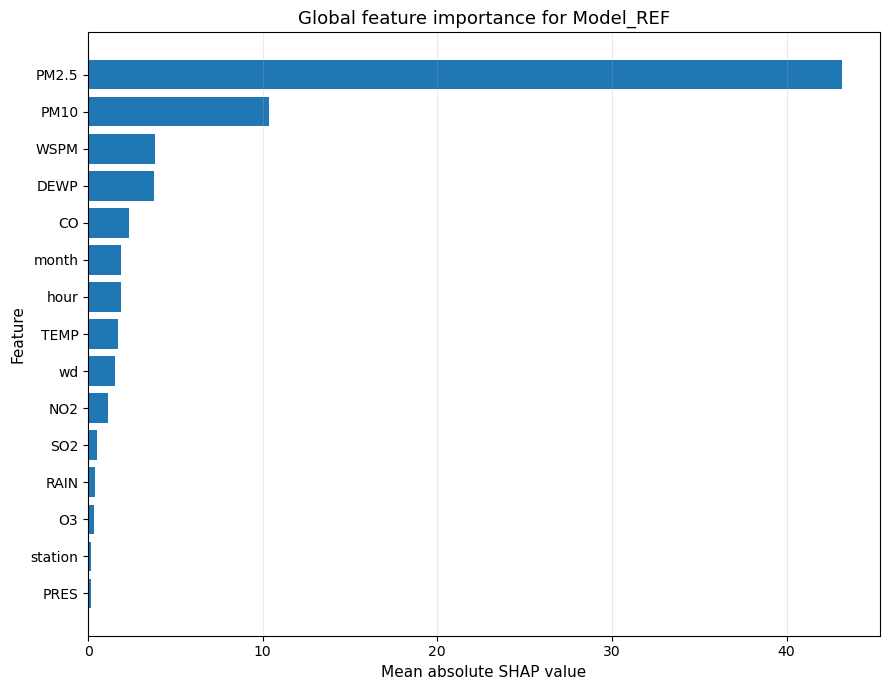

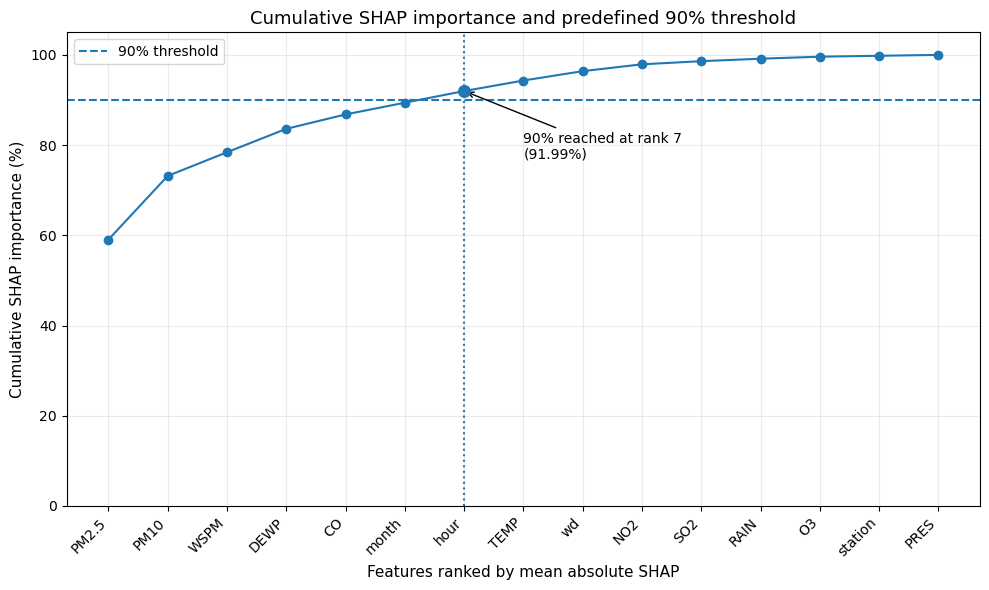

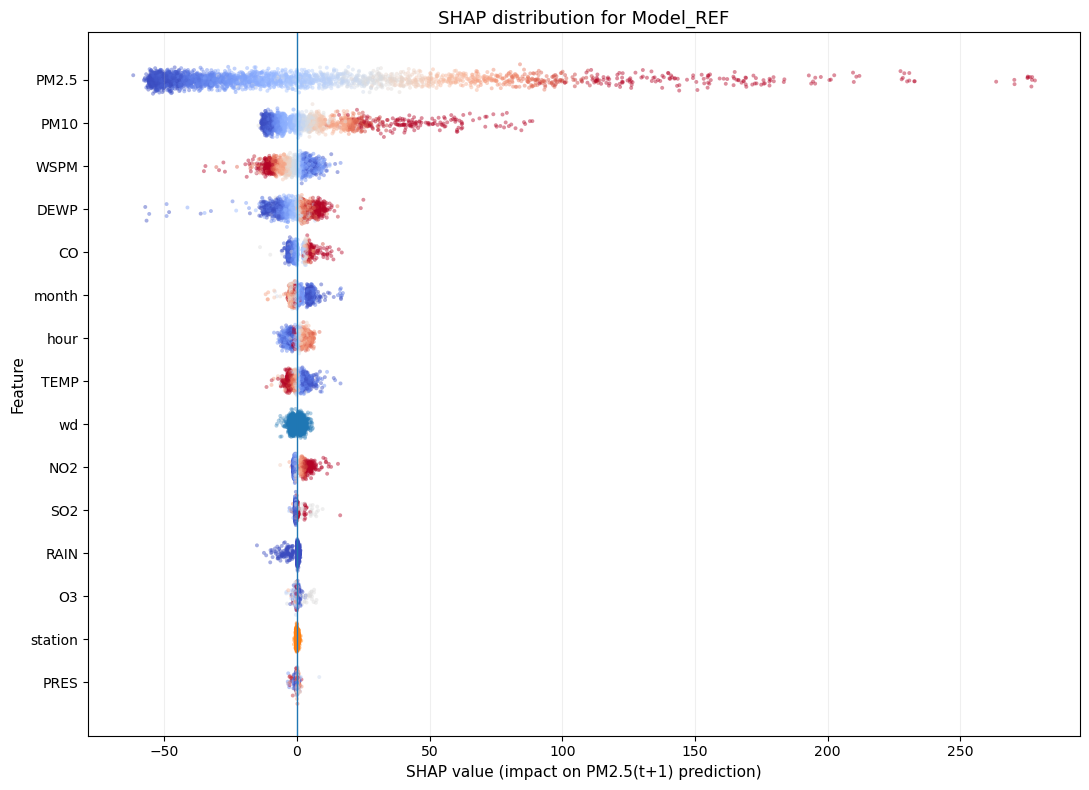


STEP 04 - SHAP_REF

TEST rows        : 102,753
SHAP sample size : 20,000
Random seed      : 42

SHAP additivity check : PASS
Maximum additivity error : 9.094947017729e-13

GLOBAL SHAP IMPORTANCE

 rank feature  mean_abs_shap  relative_importance_percent  cumulative_importance_percent  selected_90
    1   PM2.5      43.191175                    59.038962                      59.038962         True
    2    PM10      10.339728                    14.133600                      73.172562         True
    3    WSPM       3.837228                     5.245191                      78.417753         True
    4    DEWP       3.797498                     5.190884                      83.608637         True
    5      CO       2.335385                     3.192289                      86.800926         True
    6   month       1.905550                     2.604738                      89.405664         True
    7    hour       1.887070                     2.579478                      91.985141 

In [3]:
# ============================================================
# DEMARCHE_ENCAD3 - CASE STUDY 3
# STEP 04
# SHAP_REF + OBJECTIVE FEATURE SELECTION
# + PUBLICATION TABLES AND FIGURES
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import hashlib
import json
from datetime import datetime

import matplotlib.pyplot as plt

from catboost import CatBoostRegressor, Pool


# ============================================================
# 1. PATHS
# ============================================================

ROOT = Path(
    r"C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3\CASE_STUDY_3_BEIJING"
)

MODELING_VIEW_PATH = (
    ROOT / "results" / "01_reference" /
    "step02_modeling_view_ref.csv"
)

MODEL_PATH = (
    ROOT / "models" / "Model_REF.cbm"
)

OUTPUT_DIR = (
    ROOT / "results" / "02_xai_ref"
)

TABLE_DIR = OUTPUT_DIR / "tables"
FIGURE_DIR = OUTPUT_DIR / "figures"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# Main artifacts
# ------------------------------------------------------------

IMPORTANCE_PATH = (
    OUTPUT_DIR /
    "step04_shap_ref_importance.csv"
)

SHAP_VALUES_PATH = (
    OUTPUT_DIR /
    "step04_shap_ref_values.csv"
)

SAMPLE_PATH = (
    OUTPUT_DIR /
    "step04_shap_ref_sample.csv"
)

METADATA_PATH = (
    OUTPUT_DIR /
    "step04_shap_ref_metadata.json"
)


# ------------------------------------------------------------
# Publication table
# ------------------------------------------------------------

TABLE_SHAP_PATH = (
    TABLE_DIR /
    "Table_STEP04_SHAP_Global.csv"
)


# ------------------------------------------------------------
# Publication figures
# ------------------------------------------------------------

FIG_IMPORTANCE_PNG = (
    FIGURE_DIR /
    "Figure_STEP04_SHAP_Importance.png"
)

FIG_IMPORTANCE_PDF = (
    FIGURE_DIR /
    "Figure_STEP04_SHAP_Importance.pdf"
)

FIG_CUMULATIVE_PNG = (
    FIGURE_DIR /
    "Figure_STEP04_SHAP_Cumulative90.png"
)

FIG_CUMULATIVE_PDF = (
    FIGURE_DIR /
    "Figure_STEP04_SHAP_Cumulative90.pdf"
)

FIG_BEESWARM_PNG = (
    FIGURE_DIR /
    "Figure_STEP04_SHAP_Beeswarm.png"
)

FIG_BEESWARM_PDF = (
    FIGURE_DIR /
    "Figure_STEP04_SHAP_Beeswarm.pdf"
)


# ============================================================
# 2. FIXED HASHES
# ============================================================

EXPECTED_MODELING_VIEW_SHA256 = (
    "a0f2090baf731f1064d4be63769c3e62"
    "bf875a517eb1389de9518e18893f20cb"
)

EXPECTED_MODEL_SHA256 = (
    "0a7fea887b2742f0bd4830e9f0bbde801"
    "c9666bfc6f12b93d09fe0fc09992b99"
)


def sha256_file(path, chunk_size=1024 * 1024):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        while True:

            chunk = f.read(chunk_size)

            if not chunk:
                break

            h.update(chunk)

    return h.hexdigest()


actual_view_sha256 = sha256_file(
    MODELING_VIEW_PATH
)

actual_model_sha256 = sha256_file(
    MODEL_PATH
)


if actual_view_sha256 != EXPECTED_MODELING_VIEW_SHA256:

    raise RuntimeError(
        "\nModeling_View_REF SHA-256 mismatch.\n"
        f"Expected : {EXPECTED_MODELING_VIEW_SHA256}\n"
        f"Actual   : {actual_view_sha256}\n"
        "STEP 04 STOPPED."
    )


if actual_model_sha256 != EXPECTED_MODEL_SHA256:

    raise RuntimeError(
        "\nModel_REF SHA-256 mismatch.\n"
        f"Expected : {EXPECTED_MODEL_SHA256}\n"
        f"Actual   : {actual_model_sha256}\n"
        "STEP 04 STOPPED."
    )


print(
    "Modeling_View_REF SHA-256 verification : PASS"
)

print(
    "Model_REF SHA-256 verification          : PASS"
)


# ============================================================
# 3. FIXED SHAP PROTOCOL
# ============================================================

TARGET = "target_PM25_t_plus_1"

X_MODEL = [
    "PM2.5",
    "PM10",
    "SO2",
    "NO2",
    "CO",
    "O3",
    "TEMP",
    "PRES",
    "DEWP",
    "RAIN",
    "WSPM",
    "wd",
    "station",
    "hour",
    "month"
]

CATEGORICAL_FEATURES = [
    "wd",
    "station"
]

SHAP_SAMPLE_SIZE = 20000
SHAP_RANDOM_SEED = 42

CUMULATIVE_THRESHOLD = 0.90

ADDITIVITY_TOLERANCE = 1e-6


# ============================================================
# 4. LOAD MODELING VIEW
# ============================================================

df = pd.read_csv(
    MODELING_VIEW_PATH,
    low_memory=False
)


test_df = (
    df.loc[df["split"] == "TEST"]
    .copy()
    .reset_index(drop=True)
)


EXPECTED_TEST_SIZE = 102753


if len(test_df) != EXPECTED_TEST_SIZE:

    raise RuntimeError(
        "\nUnexpected TEST size.\n"
        f"Expected : {EXPECTED_TEST_SIZE}\n"
        f"Actual   : {len(test_df)}"
    )


# ============================================================
# 5. DETERMINISTIC SHAP SAMPLE
# ============================================================

if SHAP_SAMPLE_SIZE > len(test_df):

    raise RuntimeError(
        "SHAP sample size exceeds TEST size."
    )


shap_sample = (
    test_df
    .sample(
        n=SHAP_SAMPLE_SIZE,
        random_state=SHAP_RANDOM_SEED,
        replace=False
    )
    .sort_index()
    .copy()
)


# ============================================================
# 6. PREPARE FEATURES
# ============================================================

X_shap = shap_sample[X_MODEL].copy()

y_shap = shap_sample[TARGET].copy()


for col in CATEGORICAL_FEATURES:

    X_shap[col] = (
        X_shap[col]
        .fillna("__MISSING__")
        .astype(str)
    )


# ============================================================
# 7. LOAD FROZEN MODEL_REF
# ============================================================

model_ref = CatBoostRegressor()

model_ref.load_model(
    str(MODEL_PATH)
)


# ============================================================
# 8. CREATE CATBOOST POOL
# ============================================================

shap_pool = Pool(

    data=X_shap,

    label=y_shap,

    cat_features=CATEGORICAL_FEATURES
)


# ============================================================
# 9. COMPUTE SHAP VALUES
# ============================================================

print(
    "\nComputing SHAP values..."
)

shap_raw = model_ref.get_feature_importance(

    shap_pool,

    type="ShapValues"
)


expected_shape = (
    SHAP_SAMPLE_SIZE,
    len(X_MODEL) + 1
)


if shap_raw.shape != expected_shape:

    raise RuntimeError(
        "\nUnexpected SHAP matrix shape.\n"
        f"Expected : {expected_shape}\n"
        f"Actual   : {shap_raw.shape}\n"
        "STEP 04 STOPPED."
    )


shap_values = shap_raw[:, :-1]

base_values = shap_raw[:, -1]


# ============================================================
# 10. SHAP ADDITIVITY CHECK
# ============================================================

predictions = model_ref.predict(
    X_shap
)


shap_reconstructed_predictions = (

    base_values
    +
    shap_values.sum(axis=1)

)


max_additivity_error = float(

    np.max(

        np.abs(

            predictions
            -
            shap_reconstructed_predictions

        )

    )

)


additivity_pass = (

    max_additivity_error
    <= ADDITIVITY_TOLERANCE

)


if not additivity_pass:

    raise RuntimeError(
        "\nSHAP additivity check FAILED.\n"
        f"Maximum error = "
        f"{max_additivity_error}\n"
        "STEP 04 STOPPED."
    )


# ============================================================
# 11. GLOBAL SHAP IMPORTANCE
# ============================================================

mean_abs_shap = np.mean(

    np.abs(shap_values),

    axis=0
)


importance_df = pd.DataFrame({

    "feature":
        X_MODEL,

    "mean_abs_shap":
        mean_abs_shap

})


importance_df = (

    importance_df

    .sort_values(
        "mean_abs_shap",
        ascending=False
    )

    .reset_index(drop=True)

)


importance_df["rank"] = np.arange(
    1,
    len(importance_df) + 1
)


total_importance = (
    importance_df[
        "mean_abs_shap"
    ].sum()
)


if total_importance <= 0:

    raise RuntimeError(
        "Total SHAP importance is zero."
    )


importance_df[
    "relative_importance"
] = (

    importance_df["mean_abs_shap"]
    /
    total_importance

)


importance_df[
    "relative_importance_percent"
] = (

    importance_df[
        "relative_importance"
    ]
    * 100

)


importance_df[
    "cumulative_importance"
] = (

    importance_df[
        "relative_importance"
    ].cumsum()

)


importance_df[
    "cumulative_importance_percent"
] = (

    importance_df[
        "cumulative_importance"
    ]
    * 100

)


# ============================================================
# 12. OBJECTIVE 90% FEATURE SELECTION
# ============================================================

threshold_positions = np.where(

    importance_df[
        "cumulative_importance"
    ].values
    >= CUMULATIVE_THRESHOLD

)[0]


if len(threshold_positions) == 0:

    cutoff_position = (
        len(importance_df) - 1
    )

else:

    cutoff_position = int(
        threshold_positions[0]
    )


importance_df[
    "selected_90"
] = False


importance_df.loc[
    0:cutoff_position,
    "selected_90"
] = True


selected_features = (

    importance_df.loc[

        importance_df[
            "selected_90"
        ],

        "feature"

    ]

    .tolist()

)


# ============================================================
# 13. SAVE RAW SHAP VALUES
# ============================================================

shap_values_df = pd.DataFrame(

    shap_values,

    columns=[

        f"SHAP_{feature}"

        for feature in X_MODEL

    ]

)


shap_values_df.insert(

    0,

    "source_test_index",

    shap_sample.index.values

)


shap_values_df[
    "base_value"
] = base_values


shap_values_df[
    "prediction"
] = predictions


shap_values_df[
    "y_true"
] = y_shap.values


# ============================================================
# 14. SAVE SHAP SAMPLE
# ============================================================

sample_export = shap_sample.copy()


sample_export.insert(

    0,

    "source_test_index",

    shap_sample.index.values

)


# ============================================================
# 15. PUBLICATION TABLE
# ============================================================

publication_table = (

    importance_df[
        [
            "rank",
            "feature",
            "mean_abs_shap",
            "relative_importance_percent",
            "cumulative_importance_percent",
            "selected_90"
        ]
    ]

    .copy()

)


publication_table.columns = [

    "Rank",
    "Feature",
    "Mean absolute SHAP",
    "Relative importance (%)",
    "Cumulative importance (%)",
    "Selected at 90% threshold"

]


publication_table[
    "Mean absolute SHAP"
] = (

    publication_table[
        "Mean absolute SHAP"
    ].round(4)

)


publication_table[
    "Relative importance (%)"
] = (

    publication_table[
        "Relative importance (%)"
    ].round(2)

)


publication_table[
    "Cumulative importance (%)"
] = (

    publication_table[
        "Cumulative importance (%)"
    ].round(2)

)


publication_table[
    "Selected at 90% threshold"
] = (

    publication_table[
        "Selected at 90% threshold"
    ].map({
        True: "Yes",
        False: "No"
    })

)


# ============================================================
# 16. SAVE NUMERICAL ARTIFACTS
# ============================================================

importance_df.to_csv(
    IMPORTANCE_PATH,
    index=False
)

shap_values_df.to_csv(
    SHAP_VALUES_PATH,
    index=False
)

sample_export.to_csv(
    SAMPLE_PATH,
    index=False
)

publication_table.to_csv(
    TABLE_SHAP_PATH,
    index=False
)


# ============================================================
# 17. FIGURE 1
# GLOBAL MEAN ABSOLUTE SHAP IMPORTANCE
# ============================================================

plot_df = (
    importance_df
    .sort_values(
        "mean_abs_shap",
        ascending=True
    )
)


fig, ax = plt.subplots(
    figsize=(9, 7)
)


ax.barh(

    plot_df["feature"],

    plot_df["mean_abs_shap"]

)


ax.set_xlabel(
    "Mean absolute SHAP value",
    fontsize=11
)

ax.set_ylabel(
    "Feature",
    fontsize=11
)

ax.set_title(
    "Global feature importance for Model_REF",
    fontsize=13
)


ax.grid(
    axis="x",
    alpha=0.25
)


plt.tight_layout()


fig.savefig(
    FIG_IMPORTANCE_PNG,
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    FIG_IMPORTANCE_PDF,
    bbox_inches="tight"
)

plt.show()

plt.close(fig)


# ============================================================
# 18. FIGURE 2
# CUMULATIVE SHAP IMPORTANCE
# ============================================================

fig, ax = plt.subplots(
    figsize=(10, 6)
)


x_positions = np.arange(
    1,
    len(importance_df) + 1
)


ax.plot(

    x_positions,

    importance_df[
        "cumulative_importance_percent"
    ],

    marker="o"
)


ax.axhline(

    y=90,

    linestyle="--",

    linewidth=1.5,

    label="90% threshold"

)


# Exact selected cutoff
cutoff_rank = (
    cutoff_position + 1
)

cutoff_value = float(

    importance_df.loc[
        cutoff_position,
        "cumulative_importance_percent"
    ]

)


ax.axvline(

    x=cutoff_rank,

    linestyle=":",

    linewidth=1.5

)


ax.scatter(

    [cutoff_rank],

    [cutoff_value],

    s=70,

    zorder=5

)


ax.annotate(

    f"90% reached at rank {cutoff_rank}\n"
    f"({cutoff_value:.2f}%)",

    xy=(
        cutoff_rank,
        cutoff_value
    ),

    xytext=(
        min(cutoff_rank + 1, len(importance_df)),
        max(cutoff_value - 15, 10)
    ),

    arrowprops={
        "arrowstyle": "->"
    }

)


ax.set_xticks(
    x_positions
)


ax.set_xticklabels(

    importance_df["feature"],

    rotation=45,

    ha="right"
)


ax.set_ylim(
    0,
    105
)


ax.set_xlabel(
    "Features ranked by mean absolute SHAP",
    fontsize=11
)

ax.set_ylabel(
    "Cumulative SHAP importance (%)",
    fontsize=11
)

ax.set_title(
    "Cumulative SHAP importance and predefined 90% threshold",
    fontsize=13
)


ax.legend()


ax.grid(
    alpha=0.25
)


plt.tight_layout()


fig.savefig(
    FIG_CUMULATIVE_PNG,
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    FIG_CUMULATIVE_PDF,
    bbox_inches="tight"
)

plt.show()

plt.close(fig)


# ============================================================
# 19. FIGURE 3
# SHAP BEESWARM
#
# Implemented directly from SHAP values so that
# categorical predictors do not cause plotting problems.
#
# Color represents normalized feature value when numeric.
# Categorical features are plotted without a numeric color
# interpretation.
# ============================================================

# To keep the figure readable, use a deterministic subset
# of observations only for visualization.
#
# IMPORTANT:
# The GLOBAL importance above still uses ALL 20,000 rows.

BEESWARM_N = min(
    3000,
    SHAP_SAMPLE_SIZE
)


rng = np.random.default_rng(
    SHAP_RANDOM_SEED
)


beeswarm_indices = rng.choice(

    SHAP_SAMPLE_SIZE,

    size=BEESWARM_N,

    replace=False

)


# Display features in importance order
feature_order = (
    importance_df["feature"].tolist()
)


fig, ax = plt.subplots(
    figsize=(11, 8)
)


rng_jitter = np.random.default_rng(
    SHAP_RANDOM_SEED
)


for position, feature in enumerate(
    feature_order
):

    feature_index = X_MODEL.index(
        feature
    )

    shap_feature_values = (

        shap_values[
            beeswarm_indices,
            feature_index
        ]

    )

    jitter = rng_jitter.normal(

        loc=0,

        scale=0.10,

        size=BEESWARM_N

    )

    y_positions = (
        position + jitter
    )


    if feature not in CATEGORICAL_FEATURES:

        raw_values = pd.to_numeric(

            X_shap.iloc[
                beeswarm_indices
            ][feature],

            errors="coerce"

        ).to_numpy()


        finite_mask = np.isfinite(
            raw_values
        )


        normalized_values = np.full(
            BEESWARM_N,
            0.5
        )


        if finite_mask.any():

            low = np.nanpercentile(
                raw_values[finite_mask],
                5
            )

            high = np.nanpercentile(
                raw_values[finite_mask],
                95
            )


            if high > low:

                normalized_values[
                    finite_mask
                ] = np.clip(

                    (
                        raw_values[
                            finite_mask
                        ]
                        - low
                    )
                    /
                    (high - low),

                    0,
                    1

                )


        scatter = ax.scatter(

            shap_feature_values,

            y_positions,

            c=normalized_values,

            cmap="coolwarm",

            s=8,

            alpha=0.45,

            edgecolors="none"

        )

    else:

        ax.scatter(

            shap_feature_values,

            y_positions,

            s=8,

            alpha=0.35,

            edgecolors="none"

        )


ax.axvline(
    0,
    linewidth=1
)


ax.set_yticks(
    np.arange(
        len(feature_order)
    )
)


ax.set_yticklabels(
    feature_order
)


# Most important feature on top
ax.invert_yaxis()


ax.set_xlabel(
    "SHAP value (impact on PM2.5(t+1) prediction)",
    fontsize=11
)

ax.set_ylabel(
    "Feature",
    fontsize=11
)

ax.set_title(
    "SHAP distribution for Model_REF",
    fontsize=13
)


ax.grid(
    axis="x",
    alpha=0.20
)


plt.tight_layout()


fig.savefig(
    FIG_BEESWARM_PNG,
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    FIG_BEESWARM_PDF,
    bbox_inches="tight"
)

plt.show()

plt.close(fig)


# ============================================================
# 20. HASH GENERATED ARTIFACTS
# ============================================================

importance_sha256 = sha256_file(
    IMPORTANCE_PATH
)

shap_values_sha256 = sha256_file(
    SHAP_VALUES_PATH
)

sample_sha256 = sha256_file(
    SAMPLE_PATH
)

table_sha256 = sha256_file(
    TABLE_SHAP_PATH
)


# ============================================================
# 21. METADATA
# ============================================================

metadata = {

    "experiment":
        "DEMARCHE_ENCAD3_CASE_STUDY_3",

    "step":
        "04_SHAP_REF",

    "creation_time":
        datetime.now().isoformat(),

    "input": {

        "modeling_view_sha256":
            actual_view_sha256,

        "model_ref_sha256":
            actual_model_sha256

    },

    "shap_protocol": {

        "evaluation_split":
            "TEST",

        "test_rows":
            int(len(test_df)),

        "sample_size":
            SHAP_SAMPLE_SIZE,

        "sampling":
            "random_without_replacement",

        "random_seed":
            SHAP_RANDOM_SEED,

        "importance_metric":
            "mean_absolute_SHAP",

        "selection_rule":
            "smallest cumulative SHAP set >= 90%",

        "cumulative_threshold":
            CUMULATIVE_THRESHOLD

    },

    "additivity_check": {

        "tolerance":
            ADDITIVITY_TOLERANCE,

        "maximum_absolute_error":
            max_additivity_error,

        "pass":
            bool(additivity_pass)

    },

    "feature_selection": {

        "n_total_features":
            len(X_MODEL),

        "n_selected":
            len(selected_features),

        "selected_features":
            selected_features,

        "cutoff_rank":
            int(cutoff_rank),

        "cumulative_importance_at_cutoff_percent":
            cutoff_value

    },

    "figures": {

        "global_importance_png":
            str(FIG_IMPORTANCE_PNG),

        "global_importance_pdf":
            str(FIG_IMPORTANCE_PDF),

        "cumulative_90_png":
            str(FIG_CUMULATIVE_PNG),

        "cumulative_90_pdf":
            str(FIG_CUMULATIVE_PDF),

        "beeswarm_png":
            str(FIG_BEESWARM_PNG),

        "beeswarm_pdf":
            str(FIG_BEESWARM_PDF),

        "beeswarm_visualization_rows":
            BEESWARM_N

    },

    "data_quality_intervention": {

        "imputation":
            False,

        "outlier_correction":
            False,

        "measurement_correction":
            False,

        "rag_used":
            False,

        "official_documents_used_for_selection":
            False

    },

    "artifacts": {

        "importance": {

            "path":
                str(IMPORTANCE_PATH),

            "sha256":
                importance_sha256

        },

        "shap_values": {

            "path":
                str(SHAP_VALUES_PATH),

            "sha256":
                shap_values_sha256

        },

        "sample": {

            "path":
                str(SAMPLE_PATH),

            "sha256":
                sample_sha256

        },

        "publication_table": {

            "path":
                str(TABLE_SHAP_PATH),

            "sha256":
                table_sha256

        }

    }

}


with open(
    METADATA_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metadata,
        f,
        indent=4,
        ensure_ascii=False
    )


# ============================================================
# 22. FINAL REPORT
# ============================================================

print("\n" + "=" * 80)
print("STEP 04 - SHAP_REF")
print("=" * 80)


print(
    f"\nTEST rows        : "
    f"{len(test_df):,}"
)

print(
    f"SHAP sample size : "
    f"{SHAP_SAMPLE_SIZE:,}"
)

print(
    f"Random seed      : "
    f"{SHAP_RANDOM_SEED}"
)


print(
    "\nSHAP additivity check : "
    f"{'PASS' if additivity_pass else 'FAIL'}"
)

print(
    "Maximum additivity error : "
    f"{max_additivity_error:.12e}"
)


print(
    "\nGLOBAL SHAP IMPORTANCE\n"
)


display_columns = [

    "rank",

    "feature",

    "mean_abs_shap",

    "relative_importance_percent",

    "cumulative_importance_percent",

    "selected_90"

]


print(

    importance_df[
        display_columns
    ].to_string(

        index=False,

        float_format=lambda x:
            f"{x:.6f}"

    )

)


print(
    "\nSelection threshold : "
    f"{CUMULATIVE_THRESHOLD * 100:.0f}%"
)

print(
    f"Number selected     : "
    f"{len(selected_features)}"
)

print(
    "Selected features   : "
    f"{selected_features}"
)


print(
    "\nF_IMPORTANT = "
    f"{selected_features}"
)


print(
    "\nPublication table:"
)

print(
    f" - {TABLE_SHAP_PATH}"
)


print(
    "\nFigures:"
)

print(
    f" - {FIG_IMPORTANCE_PNG}"
)

print(
    f" - {FIG_IMPORTANCE_PDF}"
)

print(
    f" - {FIG_CUMULATIVE_PNG}"
)

print(
    f" - {FIG_CUMULATIVE_PDF}"
)

print(
    f" - {FIG_BEESWARM_PNG}"
)

print(
    f" - {FIG_BEESWARM_PDF}"
)


print(
    "\nTraceability artifacts:"
)

print(
    f" - {IMPORTANCE_PATH}"
)

print(
    f" - {SHAP_VALUES_PATH}"
)

print(
    f" - {SAMPLE_PATH}"
)

print(
    f" - {METADATA_PATH}"
)


print(
    "\nNo Data Quality correction performed."
)

print(
    "No RAG/documentary evidence used "
    "for feature selection."
)

print(
    "\nSTEP 04 COMPLETED."
)

Modeling_View_REF SHA-256 verification : PASS
Model_REF SHA-256 verification          : PASS

Computing DEVELOPMENT SHAP values...


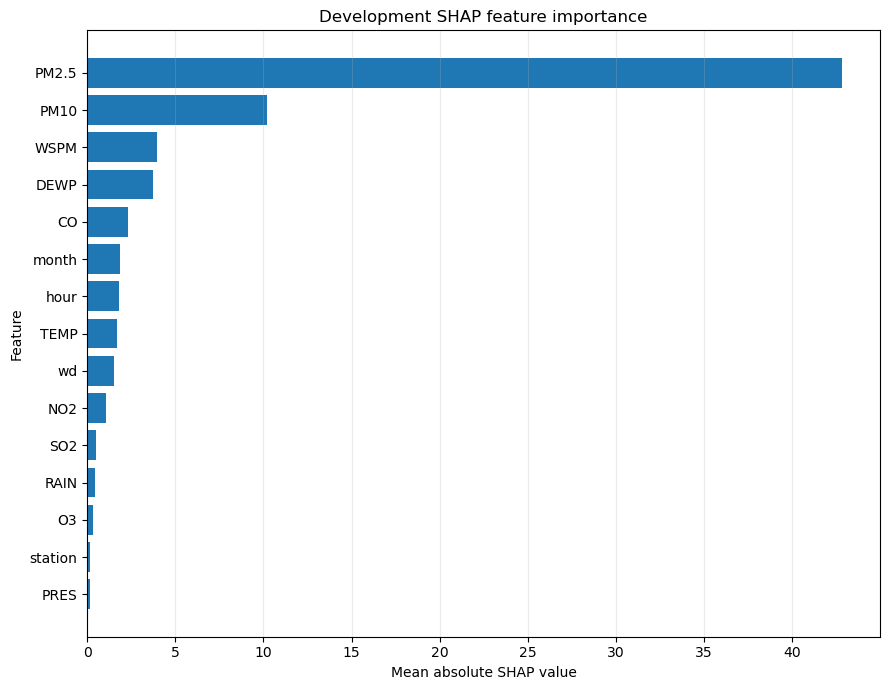

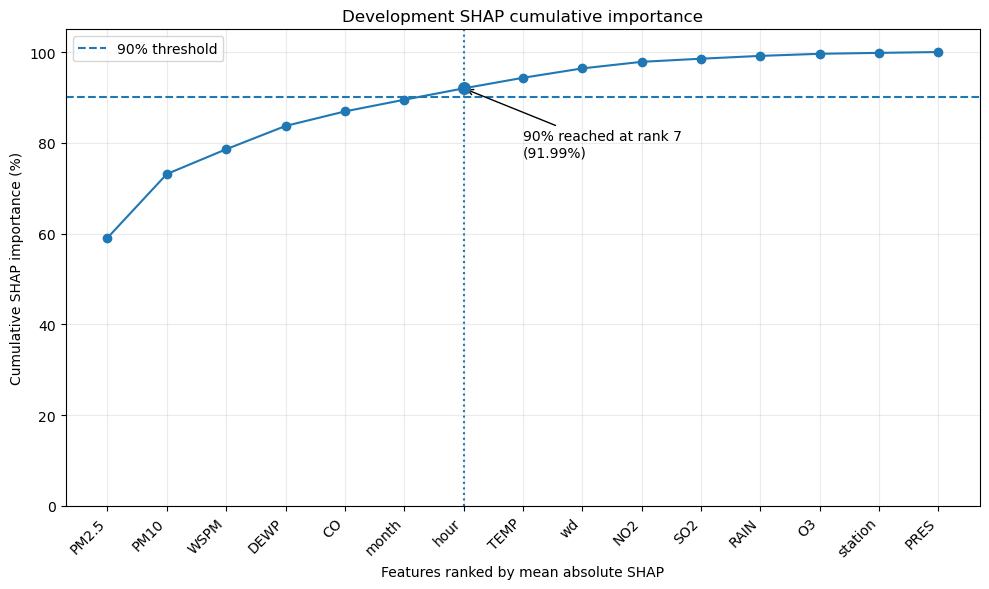

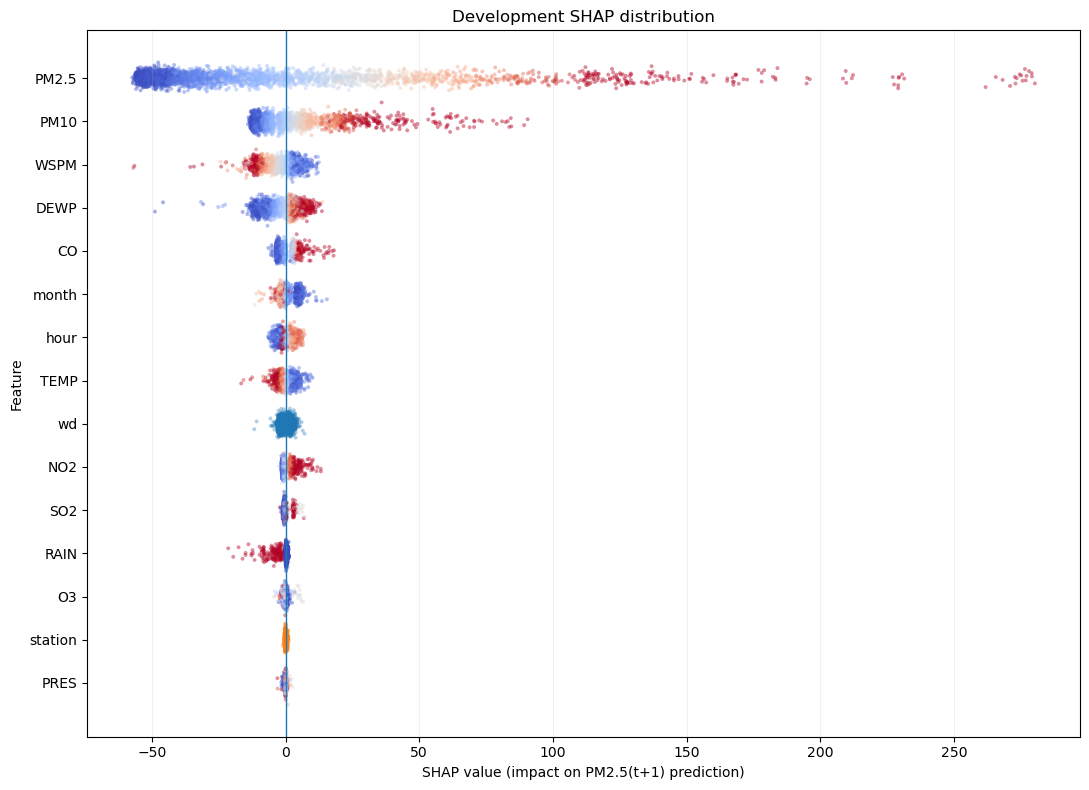


STEP 04B - SHAP DEVELOPMENT

VALIDATION rows  : 103,287
SHAP sample size : 20,000
Random seed      : 42

SHAP additivity check : PASS
Maximum additivity error : 7.958078640513e-13

DEVELOPMENT SHAP IMPORTANCE

 rank feature  mean_abs_shap  relative_importance_percent  cumulative_importance_percent  selected_90
    1   PM2.5      42.845108                    59.058965                      59.058965         True
    2    PM10      10.201763                    14.062412                      73.121377         True
    3    WSPM       3.963320                     5.463158                      78.584535         True
    4    DEWP       3.721623                     5.129995                      83.714530         True
    5      CO       2.323402                     3.202645                      86.917175         True
    6   month       1.866134                     2.572334                      89.489510         True
    7    hour       1.817183                     2.504859                  

In [4]:
# ============================================================
# DEMARCHE_ENCAD3 - CASE STUDY 3
# STEP 04B
# SHAP DEVELOPMENT ON VALIDATION
# OFFICIAL F_IMPORTANT SELECTION
# + PUBLICATION TABLES AND FIGURES
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import hashlib
import json
from datetime import datetime

import matplotlib.pyplot as plt

from catboost import CatBoostRegressor, Pool


# ============================================================
# 1. PATHS
# ============================================================

ROOT = Path(
    r"C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3\CASE_STUDY_3_BEIJING"
)

MODELING_VIEW_PATH = (
    ROOT / "results" / "01_reference" /
    "step02_modeling_view_ref.csv"
)

MODEL_PATH = (
    ROOT / "models" / "Model_REF.cbm"
)

OUTPUT_DIR = (
    ROOT / "results" / "02_xai_ref" / "development"
)

TABLE_DIR = OUTPUT_DIR / "tables"
FIGURE_DIR = OUTPUT_DIR / "figures"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)


IMPORTANCE_PATH = (
    OUTPUT_DIR /
    "step04B_shap_dev_importance.csv"
)

SHAP_VALUES_PATH = (
    OUTPUT_DIR /
    "step04B_shap_dev_values.csv"
)

SAMPLE_PATH = (
    OUTPUT_DIR /
    "step04B_shap_dev_sample.csv"
)

METADATA_PATH = (
    OUTPUT_DIR /
    "step04B_shap_dev_metadata.json"
)

TABLE_PATH = (
    TABLE_DIR /
    "Table_STEP04B_SHAP_Development.csv"
)


FIG_IMPORTANCE_PNG = (
    FIGURE_DIR /
    "Figure_STEP04B_SHAP_Importance.png"
)

FIG_IMPORTANCE_PDF = (
    FIGURE_DIR /
    "Figure_STEP04B_SHAP_Importance.pdf"
)

FIG_CUMULATIVE_PNG = (
    FIGURE_DIR /
    "Figure_STEP04B_SHAP_Cumulative90.png"
)

FIG_CUMULATIVE_PDF = (
    FIGURE_DIR /
    "Figure_STEP04B_SHAP_Cumulative90.pdf"
)

FIG_BEESWARM_PNG = (
    FIGURE_DIR /
    "Figure_STEP04B_SHAP_Beeswarm.png"
)

FIG_BEESWARM_PDF = (
    FIGURE_DIR /
    "Figure_STEP04B_SHAP_Beeswarm.pdf"
)


# ============================================================
# 2. HASH FUNCTIONS AND FIXED HASHES
# ============================================================

EXPECTED_MODELING_VIEW_SHA256 = (
    "a0f2090baf731f1064d4be63769c3e62"
    "bf875a517eb1389de9518e18893f20cb"
)

EXPECTED_MODEL_SHA256 = (
    "0a7fea887b2742f0bd4830e9f0bbde801"
    "c9666bfc6f12b93d09fe0fc09992b99"
)


def sha256_file(path, chunk_size=1024 * 1024):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        while True:

            chunk = f.read(chunk_size)

            if not chunk:
                break

            h.update(chunk)

    return h.hexdigest()


actual_view_sha256 = sha256_file(
    MODELING_VIEW_PATH
)

actual_model_sha256 = sha256_file(
    MODEL_PATH
)


if actual_view_sha256 != EXPECTED_MODELING_VIEW_SHA256:

    raise RuntimeError(
        "\nModeling_View_REF SHA-256 mismatch.\n"
        f"Expected : {EXPECTED_MODELING_VIEW_SHA256}\n"
        f"Actual   : {actual_view_sha256}\n"
        "STEP 04B STOPPED."
    )


if actual_model_sha256 != EXPECTED_MODEL_SHA256:

    raise RuntimeError(
        "\nModel_REF SHA-256 mismatch.\n"
        f"Expected : {EXPECTED_MODEL_SHA256}\n"
        f"Actual   : {actual_model_sha256}\n"
        "STEP 04B STOPPED."
    )


print(
    "Modeling_View_REF SHA-256 verification : PASS"
)

print(
    "Model_REF SHA-256 verification          : PASS"
)


# ============================================================
# 3. FIXED PROTOCOL
# ============================================================

TARGET = "target_PM25_t_plus_1"

X_MODEL = [
    "PM2.5",
    "PM10",
    "SO2",
    "NO2",
    "CO",
    "O3",
    "TEMP",
    "PRES",
    "DEWP",
    "RAIN",
    "WSPM",
    "wd",
    "station",
    "hour",
    "month"
]

CATEGORICAL_FEATURES = [
    "wd",
    "station"
]

SHAP_SAMPLE_SIZE = 20000
SHAP_RANDOM_SEED = 42

CUMULATIVE_THRESHOLD = 0.90

ADDITIVITY_TOLERANCE = 1e-6


# ============================================================
# 4. LOAD MODELING VIEW
# ============================================================

df = pd.read_csv(
    MODELING_VIEW_PATH,
    low_memory=False
)


validation_df = (
    df.loc[
        df["split"] == "VALIDATION"
    ]
    .copy()
    .reset_index(drop=True)
)


EXPECTED_VALIDATION_SIZE = 103287


if len(validation_df) != EXPECTED_VALIDATION_SIZE:

    raise RuntimeError(
        "\nUnexpected VALIDATION size.\n"
        f"Expected : {EXPECTED_VALIDATION_SIZE}\n"
        f"Actual   : {len(validation_df)}"
    )


if validation_df[TARGET].isna().any():

    raise RuntimeError(
        "VALIDATION contains missing targets."
    )


# ============================================================
# 5. DETERMINISTIC DEVELOPMENT SAMPLE
# ============================================================

if SHAP_SAMPLE_SIZE > len(validation_df):

    raise RuntimeError(
        "SHAP sample exceeds VALIDATION size."
    )


shap_sample = (
    validation_df
    .sample(
        n=SHAP_SAMPLE_SIZE,
        random_state=SHAP_RANDOM_SEED,
        replace=False
    )
    .sort_index()
    .copy()
)


# ============================================================
# 6. PREPARE FEATURES
# ============================================================

X_shap = shap_sample[X_MODEL].copy()

y_shap = shap_sample[TARGET].copy()


for col in CATEGORICAL_FEATURES:

    X_shap[col] = (
        X_shap[col]
        .fillna("__MISSING__")
        .astype(str)
    )


# ============================================================
# 7. LOAD FROZEN MODEL_REF
# ============================================================

model_ref = CatBoostRegressor()

model_ref.load_model(
    str(MODEL_PATH)
)


# ============================================================
# 8. CATBOOST POOL
# ============================================================

shap_pool = Pool(
    data=X_shap,
    label=y_shap,
    cat_features=CATEGORICAL_FEATURES
)


# ============================================================
# 9. COMPUTE SHAP
# ============================================================

print(
    "\nComputing DEVELOPMENT SHAP values..."
)


shap_raw = model_ref.get_feature_importance(
    shap_pool,
    type="ShapValues"
)


expected_shape = (
    SHAP_SAMPLE_SIZE,
    len(X_MODEL) + 1
)


if shap_raw.shape != expected_shape:

    raise RuntimeError(
        "\nUnexpected SHAP matrix shape.\n"
        f"Expected : {expected_shape}\n"
        f"Actual   : {shap_raw.shape}\n"
        "STEP 04B STOPPED."
    )


shap_values = shap_raw[:, :-1]

base_values = shap_raw[:, -1]


# ============================================================
# 10. ADDITIVITY CHECK
# ============================================================

predictions = model_ref.predict(
    X_shap
)


reconstructed_predictions = (
    base_values
    +
    shap_values.sum(axis=1)
)


max_additivity_error = float(
    np.max(
        np.abs(
            predictions
            -
            reconstructed_predictions
        )
    )
)


additivity_pass = (
    max_additivity_error
    <= ADDITIVITY_TOLERANCE
)


if not additivity_pass:

    raise RuntimeError(
        "\nSHAP additivity check FAILED.\n"
        f"Maximum error = "
        f"{max_additivity_error}\n"
        "STEP 04B STOPPED."
    )


# ============================================================
# 11. GLOBAL IMPORTANCE
# ============================================================

mean_abs_shap = np.mean(
    np.abs(shap_values),
    axis=0
)


importance_df = pd.DataFrame({
    "feature": X_MODEL,
    "mean_abs_shap": mean_abs_shap
})


importance_df = (
    importance_df
    .sort_values(
        "mean_abs_shap",
        ascending=False
    )
    .reset_index(drop=True)
)


importance_df["rank"] = np.arange(
    1,
    len(importance_df) + 1
)


total_importance = (
    importance_df[
        "mean_abs_shap"
    ].sum()
)


if total_importance <= 0:

    raise RuntimeError(
        "Total SHAP importance is zero."
    )


importance_df[
    "relative_importance"
] = (
    importance_df["mean_abs_shap"]
    /
    total_importance
)


importance_df[
    "relative_importance_percent"
] = (
    importance_df[
        "relative_importance"
    ]
    * 100
)


importance_df[
    "cumulative_importance"
] = (
    importance_df[
        "relative_importance"
    ].cumsum()
)


importance_df[
    "cumulative_importance_percent"
] = (
    importance_df[
        "cumulative_importance"
    ]
    * 100
)


# ============================================================
# 12. OFFICIAL 90% SELECTION
# ============================================================

threshold_positions = np.where(
    importance_df[
        "cumulative_importance"
    ].values
    >= CUMULATIVE_THRESHOLD
)[0]


if len(threshold_positions) == 0:

    cutoff_position = (
        len(importance_df) - 1
    )

else:

    cutoff_position = int(
        threshold_positions[0]
    )


importance_df[
    "selected_90"
] = False


importance_df.loc[
    0:cutoff_position,
    "selected_90"
] = True


selected_features = (
    importance_df.loc[
        importance_df[
            "selected_90"
        ],
        "feature"
    ]
    .tolist()
)


cutoff_rank = (
    cutoff_position + 1
)


cutoff_value = float(
    importance_df.loc[
        cutoff_position,
        "cumulative_importance_percent"
    ]
)


# ============================================================
# 13. SAVE SHAP VALUES
# ============================================================

shap_values_df = pd.DataFrame(
    shap_values,
    columns=[
        f"SHAP_{feature}"
        for feature in X_MODEL
    ]
)


shap_values_df.insert(
    0,
    "source_validation_index",
    shap_sample.index.values
)


shap_values_df[
    "base_value"
] = base_values

shap_values_df[
    "prediction"
] = predictions

shap_values_df[
    "y_true"
] = y_shap.values


# ============================================================
# 14. SAVE DEVELOPMENT SAMPLE
# ============================================================

sample_export = shap_sample.copy()


sample_export.insert(
    0,
    "source_validation_index",
    shap_sample.index.values
)


# ============================================================
# 15. PUBLICATION TABLE
# ============================================================

publication_table = (
    importance_df[
        [
            "rank",
            "feature",
            "mean_abs_shap",
            "relative_importance_percent",
            "cumulative_importance_percent",
            "selected_90"
        ]
    ]
    .copy()
)


publication_table.columns = [
    "Rank",
    "Feature",
    "Mean absolute SHAP",
    "Relative importance (%)",
    "Cumulative importance (%)",
    "Selected at 90% threshold"
]


publication_table[
    "Mean absolute SHAP"
] = (
    publication_table[
        "Mean absolute SHAP"
    ].round(4)
)


publication_table[
    "Relative importance (%)"
] = (
    publication_table[
        "Relative importance (%)"
    ].round(2)
)


publication_table[
    "Cumulative importance (%)"
] = (
    publication_table[
        "Cumulative importance (%)"
    ].round(2)
)


publication_table[
    "Selected at 90% threshold"
] = (
    publication_table[
        "Selected at 90% threshold"
    ].map({
        True: "Yes",
        False: "No"
    })
)


# ============================================================
# 16. SAVE NUMERICAL ARTIFACTS
# ============================================================

importance_df.to_csv(
    IMPORTANCE_PATH,
    index=False
)

shap_values_df.to_csv(
    SHAP_VALUES_PATH,
    index=False
)

sample_export.to_csv(
    SAMPLE_PATH,
    index=False
)

publication_table.to_csv(
    TABLE_PATH,
    index=False
)


# ============================================================
# 17. FIGURE 1
# GLOBAL SHAP IMPORTANCE
# ============================================================

plot_df = (
    importance_df
    .sort_values(
        "mean_abs_shap",
        ascending=True
    )
)


fig, ax = plt.subplots(
    figsize=(9, 7)
)


ax.barh(
    plot_df["feature"],
    plot_df["mean_abs_shap"]
)


ax.set_xlabel(
    "Mean absolute SHAP value"
)

ax.set_ylabel(
    "Feature"
)

ax.set_title(
    "Development SHAP feature importance"
)

ax.grid(
    axis="x",
    alpha=0.25
)

plt.tight_layout()


fig.savefig(
    FIG_IMPORTANCE_PNG,
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    FIG_IMPORTANCE_PDF,
    bbox_inches="tight"
)

plt.show()

plt.close(fig)


# ============================================================
# 18. FIGURE 2
# CUMULATIVE IMPORTANCE
# ============================================================

fig, ax = plt.subplots(
    figsize=(10, 6)
)


x_positions = np.arange(
    1,
    len(importance_df) + 1
)


ax.plot(
    x_positions,
    importance_df[
        "cumulative_importance_percent"
    ],
    marker="o"
)


ax.axhline(
    y=90,
    linestyle="--",
    linewidth=1.5,
    label="90% threshold"
)


ax.axvline(
    x=cutoff_rank,
    linestyle=":",
    linewidth=1.5
)


ax.scatter(
    [cutoff_rank],
    [cutoff_value],
    s=70,
    zorder=5
)


ax.annotate(
    f"90% reached at rank {cutoff_rank}\n"
    f"({cutoff_value:.2f}%)",

    xy=(
        cutoff_rank,
        cutoff_value
    ),

    xytext=(
        min(
            cutoff_rank + 1,
            len(importance_df)
        ),
        max(
            cutoff_value - 15,
            10
        )
    ),

    arrowprops={
        "arrowstyle": "->"
    }
)


ax.set_xticks(
    x_positions
)


ax.set_xticklabels(
    importance_df["feature"],
    rotation=45,
    ha="right"
)


ax.set_ylim(
    0,
    105
)


ax.set_xlabel(
    "Features ranked by mean absolute SHAP"
)

ax.set_ylabel(
    "Cumulative SHAP importance (%)"
)

ax.set_title(
    "Development SHAP cumulative importance"
)


ax.legend()

ax.grid(
    alpha=0.25
)


plt.tight_layout()


fig.savefig(
    FIG_CUMULATIVE_PNG,
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    FIG_CUMULATIVE_PDF,
    bbox_inches="tight"
)

plt.show()

plt.close(fig)


# ============================================================
# 19. FIGURE 3
# SHAP BEESWARM
#
# Visualization only.
# Global importance still uses all 20,000 rows.
# ============================================================

BEESWARM_N = min(
    3000,
    SHAP_SAMPLE_SIZE
)


rng = np.random.default_rng(
    SHAP_RANDOM_SEED
)


beeswarm_indices = rng.choice(
    SHAP_SAMPLE_SIZE,
    size=BEESWARM_N,
    replace=False
)


feature_order = (
    importance_df[
        "feature"
    ].tolist()
)


fig, ax = plt.subplots(
    figsize=(11, 8)
)


rng_jitter = np.random.default_rng(
    SHAP_RANDOM_SEED
)


for position, feature in enumerate(
    feature_order
):

    feature_index = X_MODEL.index(
        feature
    )


    shap_feature_values = (
        shap_values[
            beeswarm_indices,
            feature_index
        ]
    )


    jitter = rng_jitter.normal(
        loc=0,
        scale=0.10,
        size=BEESWARM_N
    )


    y_positions = (
        position + jitter
    )


    if feature not in CATEGORICAL_FEATURES:

        raw_values = pd.to_numeric(
            X_shap.iloc[
                beeswarm_indices
            ][feature],
            errors="coerce"
        ).to_numpy()


        finite_mask = np.isfinite(
            raw_values
        )


        normalized_values = np.full(
            BEESWARM_N,
            0.5
        )


        if finite_mask.any():

            low = np.nanpercentile(
                raw_values[
                    finite_mask
                ],
                5
            )

            high = np.nanpercentile(
                raw_values[
                    finite_mask
                ],
                95
            )


            if high > low:

                normalized_values[
                    finite_mask
                ] = np.clip(
                    (
                        raw_values[
                            finite_mask
                        ]
                        - low
                    )
                    /
                    (high - low),
                    0,
                    1
                )


        ax.scatter(
            shap_feature_values,
            y_positions,
            c=normalized_values,
            cmap="coolwarm",
            s=8,
            alpha=0.45,
            edgecolors="none"
        )


    else:

        ax.scatter(
            shap_feature_values,
            y_positions,
            s=8,
            alpha=0.35,
            edgecolors="none"
        )


ax.axvline(
    0,
    linewidth=1
)


ax.set_yticks(
    np.arange(
        len(feature_order)
    )
)


ax.set_yticklabels(
    feature_order
)


ax.invert_yaxis()


ax.set_xlabel(
    "SHAP value (impact on PM2.5(t+1) prediction)"
)

ax.set_ylabel(
    "Feature"
)

ax.set_title(
    "Development SHAP distribution"
)


ax.grid(
    axis="x",
    alpha=0.20
)


plt.tight_layout()


fig.savefig(
    FIG_BEESWARM_PNG,
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    FIG_BEESWARM_PDF,
    bbox_inches="tight"
)

plt.show()

plt.close(fig)


# ============================================================
# 20. HASH GENERATED ARTIFACTS
# ============================================================

importance_sha256 = sha256_file(
    IMPORTANCE_PATH
)

shap_values_sha256 = sha256_file(
    SHAP_VALUES_PATH
)

sample_sha256 = sha256_file(
    SAMPLE_PATH
)

table_sha256 = sha256_file(
    TABLE_PATH
)


# ============================================================
# 21. METADATA
# ============================================================

metadata = {

    "experiment":
        "DEMARCHE_ENCAD3_CASE_STUDY_3",

    "step":
        "04B_SHAP_DEVELOPMENT",

    "creation_time":
        datetime.now().isoformat(),

    "input": {

        "modeling_view_sha256":
            actual_view_sha256,

        "model_ref_sha256":
            actual_model_sha256
    },

    "methodological_role": {

        "development_split":
            "VALIDATION",

        "purpose":
            "official F_IMPORTANT selection",

        "test_used_for_feature_selection":
            False,

        "test_reserved_for_final_evaluation":
            True
    },

    "shap_protocol": {

        "validation_rows":
            int(len(validation_df)),

        "sample_size":
            SHAP_SAMPLE_SIZE,

        "sampling":
            "random_without_replacement",

        "random_seed":
            SHAP_RANDOM_SEED,

        "importance_metric":
            "mean_absolute_SHAP",

        "selection_rule":
            "smallest cumulative SHAP set >= 90%",

        "threshold":
            CUMULATIVE_THRESHOLD
    },

    "additivity_check": {

        "tolerance":
            ADDITIVITY_TOLERANCE,

        "maximum_absolute_error":
            max_additivity_error,

        "pass":
            bool(additivity_pass)
    },

    "official_feature_selection": {

        "n_total_features":
            len(X_MODEL),

        "n_selected":
            len(selected_features),

        "F_IMPORTANT":
            selected_features,

        "cutoff_rank":
            int(cutoff_rank),

        "cumulative_importance_at_cutoff_percent":
            cutoff_value
    },

    "data_quality_intervention": {

        "missing_values_corrected":
            False,

        "numerical_imputation":
            False,

        "outliers_modified":
            False,

        "measurements_corrected":
            False,

        "rag_used":
            False,

        "documentary_knowledge_used":
            False
    },

    "artifacts": {

        "importance": {
            "path":
                str(IMPORTANCE_PATH),

            "sha256":
                importance_sha256
        },

        "shap_values": {
            "path":
                str(SHAP_VALUES_PATH),

            "sha256":
                shap_values_sha256
        },

        "sample": {
            "path":
                str(SAMPLE_PATH),

            "sha256":
                sample_sha256
        },

        "publication_table": {
            "path":
                str(TABLE_PATH),

            "sha256":
                table_sha256
        }
    }
}


with open(
    METADATA_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metadata,
        f,
        indent=4,
        ensure_ascii=False
    )


# ============================================================
# 22. FINAL REPORT
# ============================================================

print("\n" + "=" * 80)
print("STEP 04B - SHAP DEVELOPMENT")
print("=" * 80)


print(
    f"\nVALIDATION rows  : "
    f"{len(validation_df):,}"
)

print(
    f"SHAP sample size : "
    f"{SHAP_SAMPLE_SIZE:,}"
)

print(
    f"Random seed      : "
    f"{SHAP_RANDOM_SEED}"
)


print(
    "\nSHAP additivity check : "
    f"{'PASS' if additivity_pass else 'FAIL'}"
)

print(
    "Maximum additivity error : "
    f"{max_additivity_error:.12e}"
)


print(
    "\nDEVELOPMENT SHAP IMPORTANCE\n"
)


display_columns = [
    "rank",
    "feature",
    "mean_abs_shap",
    "relative_importance_percent",
    "cumulative_importance_percent",
    "selected_90"
]


print(
    importance_df[
        display_columns
    ].to_string(
        index=False,
        float_format=lambda x:
            f"{x:.6f}"
    )
)


print(
    "\nSelection threshold : "
    f"{CUMULATIVE_THRESHOLD * 100:.0f}%"
)

print(
    f"Cutoff rank         : "
    f"{cutoff_rank}"
)

print(
    f"Number selected     : "
    f"{len(selected_features)}"
)


print(
    "\nOFFICIAL F_IMPORTANT:"
)

print(
    selected_features
)


print(
    "\nTEST used for this selection : NO"
)

print(
    "TEST status                  : "
    "RESERVED FOR FINAL EVALUATION"
)


print(
    "\nPublication table:"
)

print(
    f" - {TABLE_PATH}"
)


print(
    "\nFigures:"
)

print(
    f" - {FIG_IMPORTANCE_PNG}"
)

print(
    f" - {FIG_IMPORTANCE_PDF}"
)

print(
    f" - {FIG_CUMULATIVE_PNG}"
)

print(
    f" - {FIG_CUMULATIVE_PDF}"
)

print(
    f" - {FIG_BEESWARM_PNG}"
)

print(
    f" - {FIG_BEESWARM_PDF}"
)


print(
    "\nTraceability artifacts:"
)

print(
    f" - {IMPORTANCE_PATH}"
)

print(
    f" - {SHAP_VALUES_PATH}"
)

print(
    f" - {SAMPLE_PATH}"
)

print(
    f" - {METADATA_PATH}"
)


print(
    "\nNo Data Quality correction performed."
)

print(
    "No documentary knowledge used."
)

print(
    "No RAG used."
)


print(
    "\nSTEP 04B COMPLETED."
)

Modeling_View_REF SHA-256 verification : PASS

Official F_IMPORTANT loaded:
['PM2.5', 'PM10', 'WSPM', 'DEWP', 'CO', 'month', 'hour']

TRAIN rows       : 205,977
VALIDATION rows  : 103,287
DEVELOPMENT rows : 309,264
TEST used        : NO


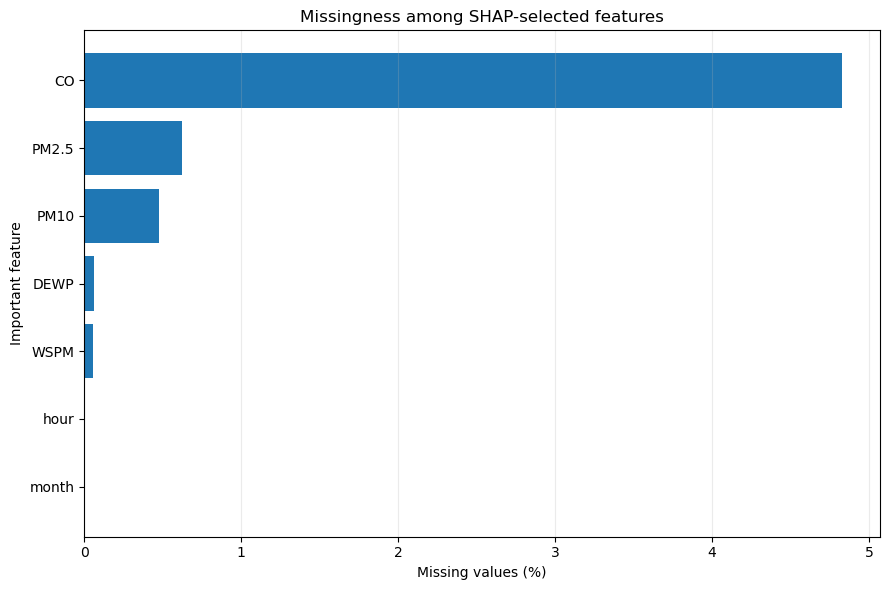

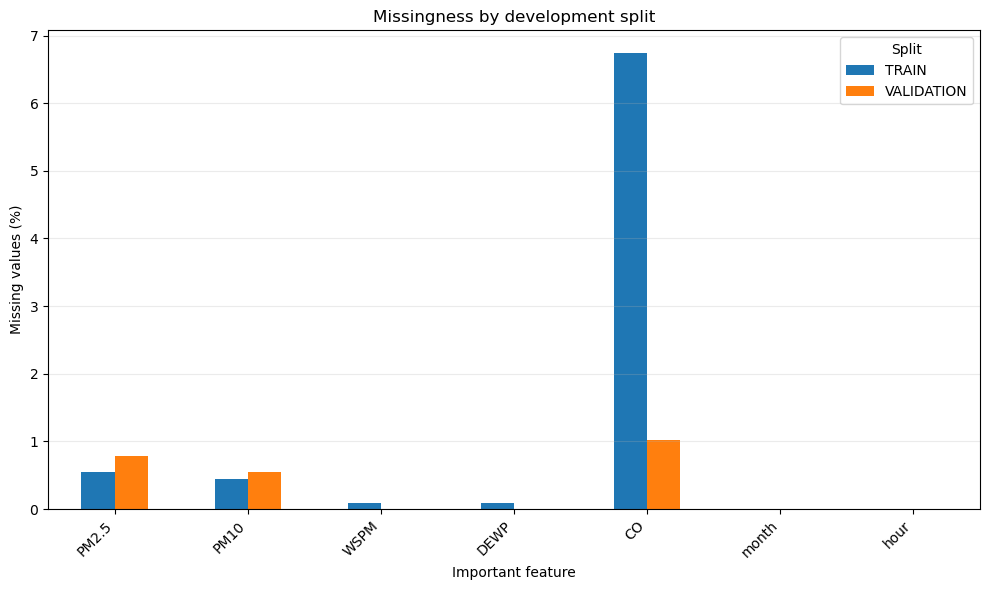

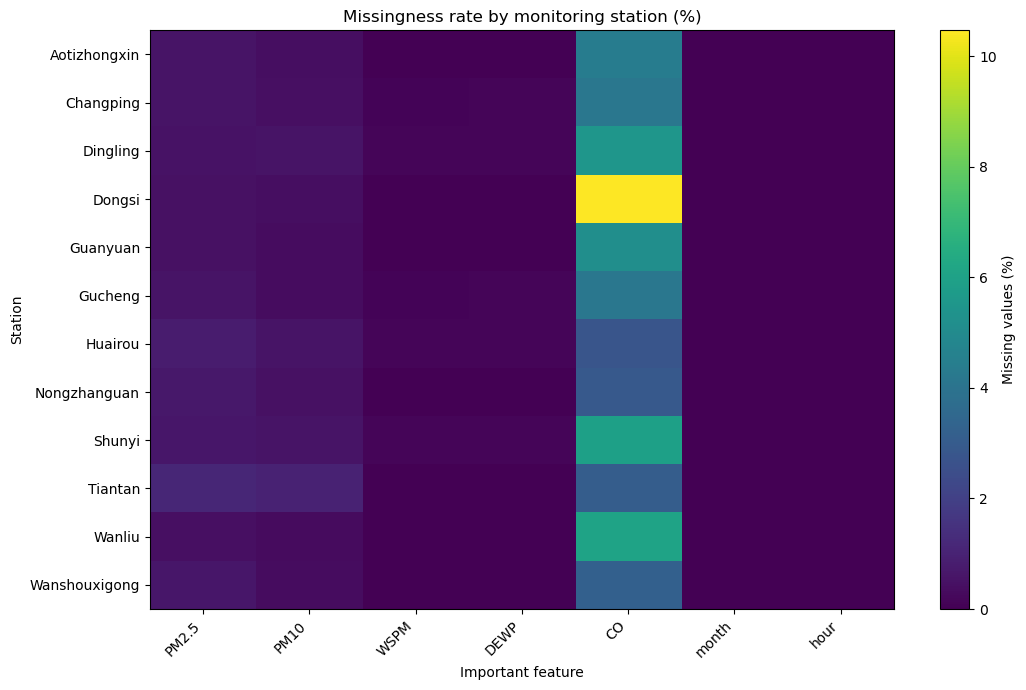


STEP 05 - TARGETED MISSING-VALUE CHARACTERIZATION

Development rows : 309,264
Splits           : TRAIN + VALIDATION
TEST used        : NO

Official F_IMPORTANT:
['PM2.5', 'PM10', 'WSPM', 'DEWP', 'CO', 'month', 'hour']

MISSING-VALUE SUMMARY

feature  n_rows  n_observed  n_missing  missing_rate_percent  problem_observed
     CO  309264      294333      14931              4.827914              True
  PM2.5  309264      307344       1920              0.620829              True
   PM10  309264      307793       1471              0.475645              True
   DEWP  309264      309082        182              0.058849              True
   WSPM  309264      309089        175              0.056586              True
  month  309264      309264          0              0.000000             False
   hour  309264      309264          0              0.000000             False

Features with observed missingness:
['CO', 'PM2.5', 'PM10', 'DEWP', 'WSPM']

Rows containing at least one missing F_IMPORTAN

In [5]:
# ============================================================
# DEMARCHE_ENCAD3 - CASE STUDY 3
# STEP 05
# TARGETED MISSING-VALUE CHARACTERIZATION
# ON OFFICIAL F_IMPORTANT
#
# DEVELOPMENT DATA ONLY: TRAIN + VALIDATION
#
# IMPORTANT:
# - Observation only
# - Missing != Error
# - Missing != automatic imputation
# - No value is modified
# - TEST remains excluded
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import hashlib
import json
from datetime import datetime

import matplotlib.pyplot as plt


# ============================================================
# 1. PATHS
# ============================================================

ROOT = Path(
    r"C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3\CASE_STUDY_3_BEIJING"
)

MODELING_VIEW_PATH = (
    ROOT / "results" / "01_reference" /
    "step02_modeling_view_ref.csv"
)

SHAP_METADATA_PATH = (
    ROOT / "results" / "02_xai_ref" / "development" /
    "step04B_shap_dev_metadata.json"
)

OUTPUT_DIR = (
    ROOT / "results" / "03_dq_diagnosis" /
    "missing_values"
)

TABLE_DIR = OUTPUT_DIR / "tables"
FIGURE_DIR = OUTPUT_DIR / "figures"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)


# ============================================================
# 2. OUTPUT FILES
# ============================================================

SUMMARY_PATH = (
    OUTPUT_DIR /
    "step05_missing_summary.csv"
)

BY_SPLIT_PATH = (
    OUTPUT_DIR /
    "step05_missing_by_split.csv"
)

BY_STATION_PATH = (
    OUTPUT_DIR /
    "step05_missing_by_station.csv"
)

PATTERNS_PATH = (
    OUTPUT_DIR /
    "step05_missing_patterns.csv"
)

METADATA_PATH = (
    OUTPUT_DIR /
    "step05_missing_metadata.json"
)


TABLE_GLOBAL_PATH = (
    TABLE_DIR /
    "Table_STEP05_Missing_Global.csv"
)

TABLE_SPLIT_PATH = (
    TABLE_DIR /
    "Table_STEP05_Missing_By_Split.csv"
)


FIG_RATE_PNG = (
    FIGURE_DIR /
    "Figure_STEP05_Missing_Rate.png"
)

FIG_RATE_PDF = (
    FIGURE_DIR /
    "Figure_STEP05_Missing_Rate.pdf"
)

FIG_SPLIT_PNG = (
    FIGURE_DIR /
    "Figure_STEP05_Missing_By_Split.png"
)

FIG_SPLIT_PDF = (
    FIGURE_DIR /
    "Figure_STEP05_Missing_By_Split.pdf"
)

FIG_STATION_PNG = (
    FIGURE_DIR /
    "Figure_STEP05_Missing_By_Station.png"
)

FIG_STATION_PDF = (
    FIGURE_DIR /
    "Figure_STEP05_Missing_By_Station.pdf"
)


# ============================================================
# 3. HASH FUNCTION
# ============================================================

def sha256_file(path, chunk_size=1024 * 1024):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        while True:

            chunk = f.read(chunk_size)

            if not chunk:
                break

            h.update(chunk)

    return h.hexdigest()


EXPECTED_MODELING_VIEW_SHA256 = (
    "a0f2090baf731f1064d4be63769c3e62"
    "bf875a517eb1389de9518e18893f20cb"
)


actual_view_sha256 = sha256_file(
    MODELING_VIEW_PATH
)


if actual_view_sha256 != EXPECTED_MODELING_VIEW_SHA256:

    raise RuntimeError(
        "\nModeling_View_REF SHA-256 mismatch.\n"
        f"Expected : {EXPECTED_MODELING_VIEW_SHA256}\n"
        f"Actual   : {actual_view_sha256}\n"
        "STEP 05 STOPPED."
    )


print(
    "Modeling_View_REF SHA-256 verification : PASS"
)


# ============================================================
# 4. LOAD OFFICIAL F_IMPORTANT FROM STEP 04B
# ============================================================

with open(
    SHAP_METADATA_PATH,
    "r",
    encoding="utf-8"
) as f:

    shap_metadata = json.load(f)


F_IMPORTANT = (
    shap_metadata[
        "official_feature_selection"
    ][
        "F_IMPORTANT"
    ]
)


EXPECTED_F_IMPORTANT = [
    "PM2.5",
    "PM10",
    "WSPM",
    "DEWP",
    "CO",
    "month",
    "hour"
]


if F_IMPORTANT != EXPECTED_F_IMPORTANT:

    raise RuntimeError(
        "\nUnexpected F_IMPORTANT.\n"
        f"Expected : {EXPECTED_F_IMPORTANT}\n"
        f"Actual   : {F_IMPORTANT}\n"
        "STEP 05 STOPPED."
    )


print(
    "\nOfficial F_IMPORTANT loaded:"
)

print(
    F_IMPORTANT
)


# ============================================================
# 5. LOAD MODELING VIEW
# ============================================================

df = pd.read_csv(
    MODELING_VIEW_PATH,
    low_memory=False
)


# ============================================================
# 6. DEVELOPMENT DATA ONLY
# ============================================================

development_df = (
    df.loc[
        df["split"].isin(
            ["TRAIN", "VALIDATION"]
        )
    ]
    .copy()
)


n_development = len(
    development_df
)


n_train = int(
    (
        development_df["split"]
        == "TRAIN"
    ).sum()
)


n_validation = int(
    (
        development_df["split"]
        == "VALIDATION"
    ).sum()
)


EXPECTED_TRAIN = 205977
EXPECTED_VALIDATION = 103287
EXPECTED_DEVELOPMENT = (
    EXPECTED_TRAIN
    +
    EXPECTED_VALIDATION
)


if n_train != EXPECTED_TRAIN:

    raise RuntimeError(
        f"Unexpected TRAIN size: {n_train}"
    )


if n_validation != EXPECTED_VALIDATION:

    raise RuntimeError(
        "Unexpected VALIDATION size: "
        f"{n_validation}"
    )


if n_development != EXPECTED_DEVELOPMENT:

    raise RuntimeError(
        "Unexpected DEVELOPMENT size: "
        f"{n_development}"
    )


print(
    f"\nTRAIN rows       : {n_train:,}"
)

print(
    f"VALIDATION rows  : {n_validation:,}"
)

print(
    f"DEVELOPMENT rows : {n_development:,}"
)

print(
    "TEST used        : NO"
)


# ============================================================
# 7. GLOBAL MISSING SUMMARY
# ============================================================

summary_records = []


for feature in F_IMPORTANT:

    n_missing = int(
        development_df[
            feature
        ].isna().sum()
    )

    missing_rate = (
        n_missing
        /
        n_development
        *
        100
    )

    n_observed = (
        n_development
        -
        n_missing
    )

    summary_records.append({

        "feature":
            feature,

        "n_rows":
            n_development,

        "n_observed":
            n_observed,

        "n_missing":
            n_missing,

        "missing_rate_percent":
            missing_rate,

        "problem_observed":
            n_missing > 0

    })


summary_df = pd.DataFrame(
    summary_records
)


summary_df = (
    summary_df
    .sort_values(
        "missing_rate_percent",
        ascending=False
    )
    .reset_index(drop=True)
)


# ============================================================
# 8. MISSING BY SPLIT
# ============================================================

split_records = []


for split_name in [
    "TRAIN",
    "VALIDATION"
]:

    split_df = (
        development_df.loc[
            development_df["split"]
            == split_name
        ]
    )

    n_split = len(
        split_df
    )


    for feature in F_IMPORTANT:

        n_missing = int(
            split_df[
                feature
            ].isna().sum()
        )

        missing_rate = (
            n_missing
            /
            n_split
            *
            100
        )


        split_records.append({

            "split":
                split_name,

            "feature":
                feature,

            "n_rows":
                n_split,

            "n_missing":
                n_missing,

            "missing_rate_percent":
                missing_rate

        })


by_split_df = pd.DataFrame(
    split_records
)


# ============================================================
# 9. MISSING BY STATION
# ============================================================

station_records = []


stations = sorted(
    development_df[
        "station"
    ].dropna().unique()
)


for station in stations:

    station_df = (
        development_df.loc[
            development_df["station"]
            == station
        ]
    )

    n_station = len(
        station_df
    )


    for feature in F_IMPORTANT:

        n_missing = int(
            station_df[
                feature
            ].isna().sum()
        )


        missing_rate = (
            n_missing
            /
            n_station
            *
            100
        )


        station_records.append({

            "station":
                station,

            "feature":
                feature,

            "n_rows":
                n_station,

            "n_missing":
                n_missing,

            "missing_rate_percent":
                missing_rate

        })


by_station_df = pd.DataFrame(
    station_records
)


# ============================================================
# 10. ROW-LEVEL MISSING PATTERNS
# ============================================================

missing_matrix = (
    development_df[
        F_IMPORTANT
    ].isna()
)


def create_missing_pattern(row):

    missing_features = [

        feature

        for feature in F_IMPORTANT

        if row[feature]

    ]


    if len(missing_features) == 0:

        return "NO_MISSING"


    return " + ".join(
        missing_features
    )


missing_patterns = (
    missing_matrix
    .apply(
        create_missing_pattern,
        axis=1
    )
)


patterns_df = (
    missing_patterns
    .value_counts(
        dropna=False
    )
    .rename_axis(
        "missing_pattern"
    )
    .reset_index(
        name="n_rows"
    )
)


patterns_df[
    "rate_percent"
] = (
    patterns_df[
        "n_rows"
    ]
    /
    n_development
    *
    100
)


patterns_df[
    "contains_missing"
] = (
    patterns_df[
        "missing_pattern"
    ]
    != "NO_MISSING"
)


# ============================================================
# 11. ROWS AFFECTED BY AT LEAST ONE MISSING
# ============================================================

row_has_missing = (
    missing_matrix.any(
        axis=1
    )
)


n_rows_with_missing = int(
    row_has_missing.sum()
)


rate_rows_with_missing = (
    n_rows_with_missing
    /
    n_development
    *
    100
)


# ============================================================
# 12. IDENTIFY FEATURES WITH OBSERVED MISSINGNESS
# ============================================================

F_MISSING = (
    summary_df.loc[
        summary_df[
            "problem_observed"
        ],
        "feature"
    ]
    .tolist()
)


# ============================================================
# 13. SAVE NUMERICAL RESULTS
# ============================================================

summary_df.to_csv(
    SUMMARY_PATH,
    index=False
)

by_split_df.to_csv(
    BY_SPLIT_PATH,
    index=False
)

by_station_df.to_csv(
    BY_STATION_PATH,
    index=False
)

patterns_df.to_csv(
    PATTERNS_PATH,
    index=False
)


# ============================================================
# 14. PUBLICATION TABLE 1
# ============================================================

table_global = (
    summary_df[
        [
            "feature",
            "n_observed",
            "n_missing",
            "missing_rate_percent",
            "problem_observed"
        ]
    ]
    .copy()
)


table_global.columns = [
    "Feature",
    "Observed values",
    "Missing values",
    "Missing rate (%)",
    "Missingness observed"
]


table_global[
    "Missing rate (%)"
] = (
    table_global[
        "Missing rate (%)"
    ].round(3)
)


table_global[
    "Missingness observed"
] = (
    table_global[
        "Missingness observed"
    ].map({
        True: "Yes",
        False: "No"
    })
)


table_global.to_csv(
    TABLE_GLOBAL_PATH,
    index=False
)


# ============================================================
# 15. PUBLICATION TABLE 2
# ============================================================

table_split = (
    by_split_df.pivot(
        index="feature",
        columns="split",
        values=[
            "n_missing",
            "missing_rate_percent"
        ]
    )
)


table_split.columns = [
    "_".join(
        col
    ).strip()
    for col in table_split.columns.values
]


table_split = (
    table_split
    .reset_index()
)


for col in table_split.columns:

    if "missing_rate_percent" in col:

        table_split[col] = (
            table_split[col]
            .round(3)
        )


table_split.to_csv(
    TABLE_SPLIT_PATH,
    index=False
)


# ============================================================
# 16. FIGURE 1
# GLOBAL MISSING RATE
# ============================================================

plot_df = (
    summary_df
    .sort_values(
        "missing_rate_percent",
        ascending=True
    )
)


fig, ax = plt.subplots(
    figsize=(9, 6)
)


ax.barh(
    plot_df["feature"],
    plot_df[
        "missing_rate_percent"
    ]
)


ax.set_xlabel(
    "Missing values (%)"
)

ax.set_ylabel(
    "Important feature"
)

ax.set_title(
    "Missingness among SHAP-selected features"
)


ax.grid(
    axis="x",
    alpha=0.25
)


plt.tight_layout()


fig.savefig(
    FIG_RATE_PNG,
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    FIG_RATE_PDF,
    bbox_inches="tight"
)

plt.show()

plt.close(fig)


# ============================================================
# 17. FIGURE 2
# MISSING RATE BY SPLIT
# ============================================================

split_plot = (
    by_split_df
    .pivot(
        index="feature",
        columns="split",
        values="missing_rate_percent"
    )
    .reindex(
        F_IMPORTANT
    )
)


ax = split_plot.plot(
    kind="bar",
    figsize=(10, 6)
)


ax.set_xlabel(
    "Important feature"
)

ax.set_ylabel(
    "Missing values (%)"
)

ax.set_title(
    "Missingness by development split"
)


ax.legend(
    title="Split"
)


ax.grid(
    axis="y",
    alpha=0.25
)


plt.xticks(
    rotation=45,
    ha="right"
)


plt.tight_layout()


fig = ax.get_figure()


fig.savefig(
    FIG_SPLIT_PNG,
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    FIG_SPLIT_PDF,
    bbox_inches="tight"
)

plt.show()

plt.close(fig)


# ============================================================
# 18. FIGURE 3
# MISSINGNESS BY STATION
# HEATMAP WITHOUT SEABORN
# ============================================================

station_matrix = (
    by_station_df
    .pivot(
        index="station",
        columns="feature",
        values="missing_rate_percent"
    )
    .reindex(
        columns=F_IMPORTANT
    )
)


fig, ax = plt.subplots(
    figsize=(11, 7)
)


image = ax.imshow(
    station_matrix.values,
    aspect="auto"
)


ax.set_xticks(
    np.arange(
        len(station_matrix.columns)
    )
)


ax.set_xticklabels(
    station_matrix.columns,
    rotation=45,
    ha="right"
)


ax.set_yticks(
    np.arange(
        len(station_matrix.index)
    )
)


ax.set_yticklabels(
    station_matrix.index
)


ax.set_xlabel(
    "Important feature"
)

ax.set_ylabel(
    "Station"
)

ax.set_title(
    "Missingness rate by monitoring station (%)"
)


colorbar = fig.colorbar(
    image,
    ax=ax
)


colorbar.set_label(
    "Missing values (%)"
)


plt.tight_layout()


fig.savefig(
    FIG_STATION_PNG,
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    FIG_STATION_PDF,
    bbox_inches="tight"
)

plt.show()

plt.close(fig)


# ============================================================
# 19. HASH OUTPUT ARTIFACTS
# ============================================================

artifact_hashes = {}


for path in [
    SUMMARY_PATH,
    BY_SPLIT_PATH,
    BY_STATION_PATH,
    PATTERNS_PATH,
    TABLE_GLOBAL_PATH,
    TABLE_SPLIT_PATH
]:

    artifact_hashes[
        path.name
    ] = sha256_file(
        path
    )


# ============================================================
# 20. METADATA
# ============================================================

metadata = {

    "experiment":
        "DEMARCHE_ENCAD3_CASE_STUDY_3",

    "step":
        "05_TARGETED_MISSING_CHARACTERIZATION",

    "creation_time":
        datetime.now().isoformat(),

    "input": {

        "modeling_view_sha256":
            actual_view_sha256,

        "F_IMPORTANT_source":
            str(SHAP_METADATA_PATH),

        "F_IMPORTANT":
            F_IMPORTANT
    },

    "development_scope": {

        "splits": [
            "TRAIN",
            "VALIDATION"
        ],

        "train_rows":
            n_train,

        "validation_rows":
            n_validation,

        "total_rows":
            n_development,

        "test_used":
            False
    },

    "missing_observation": {

        "features_with_missing":
            F_MISSING,

        "n_features_with_missing":
            len(F_MISSING),

        "rows_with_at_least_one_missing":
            n_rows_with_missing,

        "rate_rows_with_at_least_one_missing_percent":
            rate_rows_with_missing
    },

    "epistemic_status": {

        "missing_means_error":
            False,

        "missing_means_impute":
            False,

        "error_diagnosis_performed":
            False,

        "correction_performed":
            False,

        "documentary_evidence_used":
            False,

        "rag_used":
            False
    },

    "artifacts_sha256":
        artifact_hashes
}


with open(
    METADATA_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metadata,
        f,
        indent=4,
        ensure_ascii=False
    )


# ============================================================
# 21. FINAL REPORT
# ============================================================

print("\n" + "=" * 80)
print("STEP 05 - TARGETED MISSING-VALUE CHARACTERIZATION")
print("=" * 80)


print(
    f"\nDevelopment rows : "
    f"{n_development:,}"
)

print(
    "Splits           : TRAIN + VALIDATION"
)

print(
    "TEST used        : NO"
)


print(
    "\nOfficial F_IMPORTANT:"
)

print(
    F_IMPORTANT
)


print(
    "\nMISSING-VALUE SUMMARY\n"
)


print(
    summary_df.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.6f}"
    )
)


print(
    "\nFeatures with observed missingness:"
)

print(
    F_MISSING
)


print(
    "\nRows containing at least one missing "
    "F_IMPORTANT value:"
)

print(
    f"{n_rows_with_missing:,} / "
    f"{n_development:,} "
    f"({rate_rows_with_missing:.4f}%)"
)


print(
    "\nMost frequent missingness patterns:\n"
)


print(
    patterns_df.head(15).to_string(
        index=False,
        float_format=lambda x:
            f"{x:.6f}"
    )
)


print(
    "\nPublication tables:"
)

print(
    f" - {TABLE_GLOBAL_PATH}"
)

print(
    f" - {TABLE_SPLIT_PATH}"
)


print(
    "\nFigures:"
)

print(
    f" - {FIG_RATE_PNG}"
)

print(
    f" - {FIG_RATE_PDF}"
)

print(
    f" - {FIG_SPLIT_PNG}"
)

print(
    f" - {FIG_SPLIT_PDF}"
)

print(
    f" - {FIG_STATION_PNG}"
)

print(
    f" - {FIG_STATION_PDF}"
)


print(
    "\nTraceability artifacts:"
)

print(
    f" - {SUMMARY_PATH}"
)

print(
    f" - {BY_SPLIT_PATH}"
)

print(
    f" - {BY_STATION_PATH}"
)

print(
    f" - {PATTERNS_PATH}"
)

print(
    f" - {METADATA_PATH}"
)


print(
    "\nIMPORTANT:"
)

print(
    "Observed missingness is NOT classified as error."
)

print(
    "No missing value was imputed."
)

print(
    "No measurement was corrected."
)

print(
    "No documentary knowledge was used."
)

print(
    "No RAG was used."
)


print(
    "\nSTEP 05 COMPLETED."
)

Modeling_View_REF SHA-256 verification : PASS

Official F_IMPORTANT:
['PM2.5', 'PM10', 'WSPM', 'DEWP', 'CO', 'month', 'hour']

Measured features evaluated for potential outliers:
['PM2.5', 'PM10', 'WSPM', 'DEWP', 'CO']

Structural features excluded:
['month', 'hour']

TRAIN rows       : 205,977
VALIDATION rows  : 103,287
DEVELOPMENT rows : 309,264
TEST used        : NO

Processing PM2.5...

Processing PM10...

Processing WSPM...

Processing DEWP...

Processing CO...


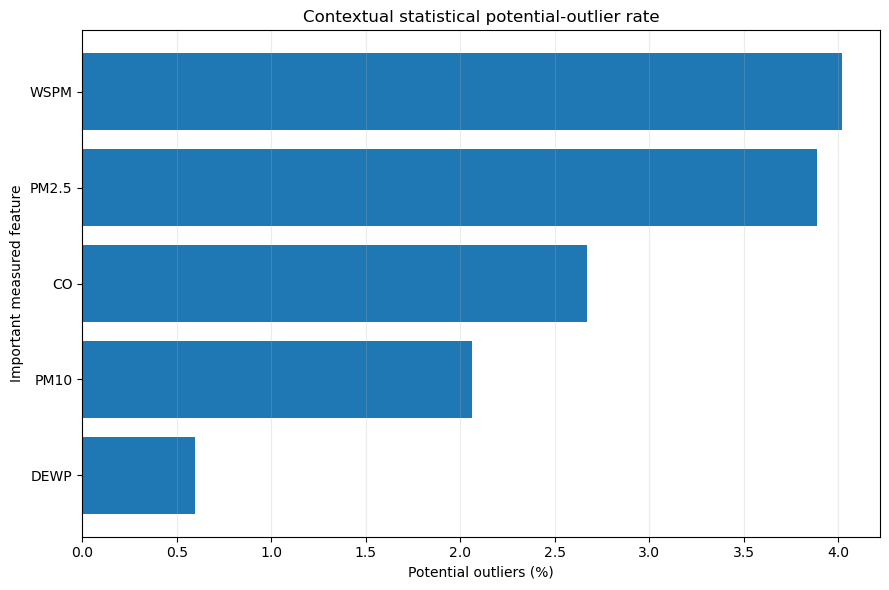

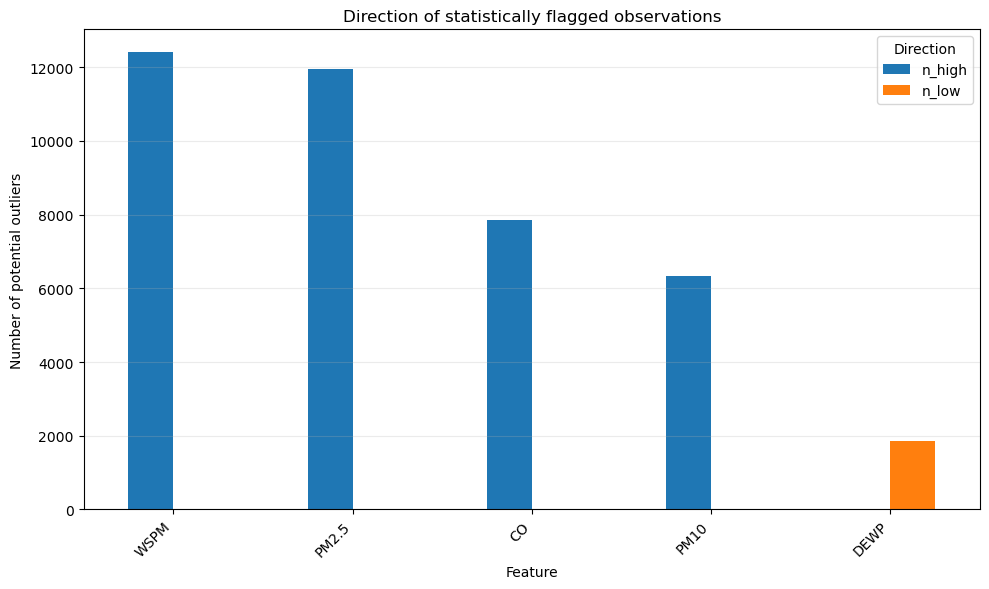

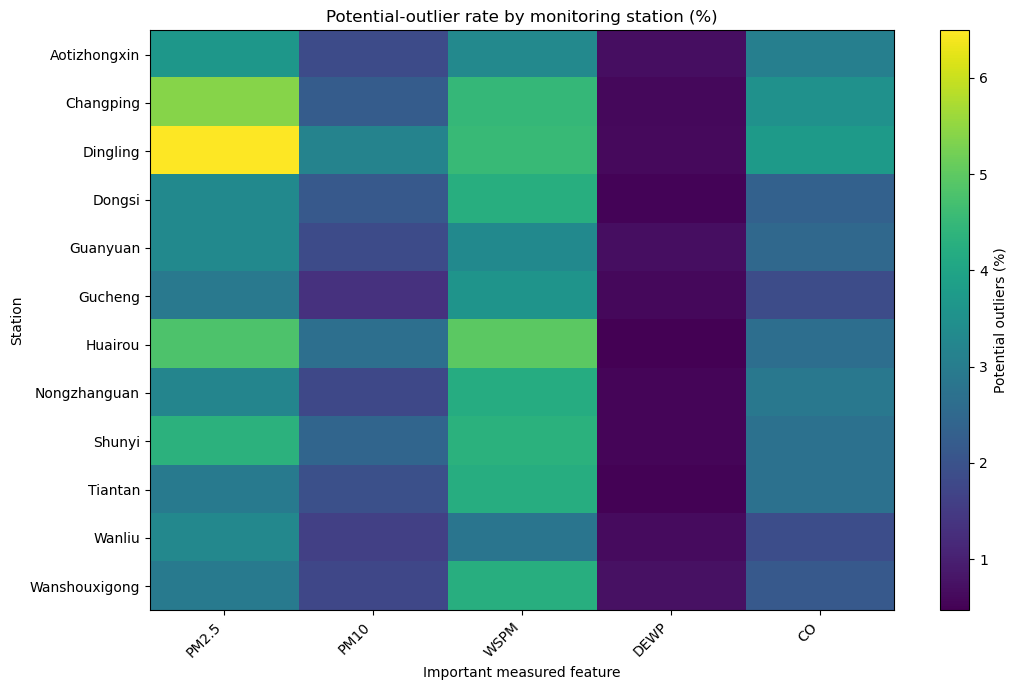


STEP 06 - CONTEXTUAL POTENTIAL-OUTLIER DETECTION

Development rows : 309,264
Splits           : TRAIN + VALIDATION
TEST used        : NO

Features analyzed:
['PM2.5', 'PM10', 'WSPM', 'DEWP', 'CO']

Context:
station × month × hour

Detector:
Median + MAD + Modified Z-score
Threshold         : |Modified Z| > 3.5
Minimum group size: 30

POTENTIAL-OUTLIER SUMMARY

feature  n_observed  n_context_eligible  n_small_context  n_zero_mad  n_potential_outlier  n_high  n_low  potential_outlier_rate_percent
   WSPM      309089              309089                0           0                12423   12410     13                        4.019231
  PM2.5      307344              307344                0           0                11951   11951      0                        3.888477
     CO      294333              294333                0           0                 7864    7864      0                        2.671804
   PM10      307793              307793                0           0                 634

In [6]:
# ============================================================
# DEMARCHE_ENCAD3 - CASE STUDY 3
# STEP 06
# CONTEXTUAL ROBUST DETECTION OF POTENTIAL OUTLIERS
#
# DEVELOPMENT ONLY: TRAIN + VALIDATION
#
# Statistical detector:
# station × month × hour contextual groups
# Median + MAD
# Modified Z-score threshold = 3.5
#
# IMPORTANT:
# Statistical outlier != Error
# Extreme value != Invalid value
# No observation is corrected/deleted/replaced
# TEST remains excluded
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import hashlib
import json
from datetime import datetime
import matplotlib.pyplot as plt


# ============================================================
# 1. PATHS
# ============================================================

ROOT = Path(
    r"C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3\CASE_STUDY_3_BEIJING"
)

MODELING_VIEW_PATH = (
    ROOT / "results" / "01_reference" /
    "step02_modeling_view_ref.csv"
)

SHAP_METADATA_PATH = (
    ROOT / "results" / "02_xai_ref" / "development" /
    "step04B_shap_dev_metadata.json"
)

OUTPUT_DIR = (
    ROOT / "results" / "03_dq_diagnosis" /
    "potential_outliers"
)

TABLE_DIR = OUTPUT_DIR / "tables"
FIGURE_DIR = OUTPUT_DIR / "figures"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)


SUMMARY_PATH = (
    OUTPUT_DIR /
    "step06_outlier_summary.csv"
)

OBSERVATIONS_PATH = (
    OUTPUT_DIR /
    "step06_outlier_observations.csv"
)

BY_STATION_PATH = (
    OUTPUT_DIR /
    "step06_outlier_by_station.csv"
)

BY_SPLIT_PATH = (
    OUTPUT_DIR /
    "step06_outlier_by_split.csv"
)

METADATA_PATH = (
    OUTPUT_DIR /
    "step06_outlier_metadata.json"
)


TABLE_GLOBAL_PATH = (
    TABLE_DIR /
    "Table_STEP06_Outlier_Global.csv"
)

TABLE_SPLIT_PATH = (
    TABLE_DIR /
    "Table_STEP06_Outlier_By_Split.csv"
)


FIG_RATE_PNG = (
    FIGURE_DIR /
    "Figure_STEP06_Outlier_Rate.png"
)

FIG_RATE_PDF = (
    FIGURE_DIR /
    "Figure_STEP06_Outlier_Rate.pdf"
)

FIG_DIRECTION_PNG = (
    FIGURE_DIR /
    "Figure_STEP06_Outlier_By_Feature.png"
)

FIG_DIRECTION_PDF = (
    FIGURE_DIR /
    "Figure_STEP06_Outlier_By_Feature.pdf"
)

FIG_STATION_PNG = (
    FIGURE_DIR /
    "Figure_STEP06_Outlier_By_Station.png"
)

FIG_STATION_PDF = (
    FIGURE_DIR /
    "Figure_STEP06_Outlier_By_Station.pdf"
)


# ============================================================
# 2. HASH FUNCTION
# ============================================================

def sha256_file(path, chunk_size=1024 * 1024):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        while True:

            chunk = f.read(chunk_size)

            if not chunk:
                break

            h.update(chunk)

    return h.hexdigest()


EXPECTED_MODELING_VIEW_SHA256 = (
    "a0f2090baf731f1064d4be63769c3e62"
    "bf875a517eb1389de9518e18893f20cb"
)


actual_view_sha256 = sha256_file(
    MODELING_VIEW_PATH
)


if actual_view_sha256 != EXPECTED_MODELING_VIEW_SHA256:

    raise RuntimeError(
        "\nModeling_View_REF SHA-256 mismatch.\n"
        f"Expected : {EXPECTED_MODELING_VIEW_SHA256}\n"
        f"Actual   : {actual_view_sha256}\n"
        "STEP 06 STOPPED."
    )


print(
    "Modeling_View_REF SHA-256 verification : PASS"
)


# ============================================================
# 3. LOAD OFFICIAL F_IMPORTANT
# ============================================================

with open(
    SHAP_METADATA_PATH,
    "r",
    encoding="utf-8"
) as f:

    shap_metadata = json.load(f)


F_IMPORTANT = (
    shap_metadata[
        "official_feature_selection"
    ][
        "F_IMPORTANT"
    ]
)


EXPECTED_F_IMPORTANT = [
    "PM2.5",
    "PM10",
    "WSPM",
    "DEWP",
    "CO",
    "month",
    "hour"
]


if F_IMPORTANT != EXPECTED_F_IMPORTANT:

    raise RuntimeError(
        "\nUnexpected F_IMPORTANT.\n"
        f"Expected : {EXPECTED_F_IMPORTANT}\n"
        f"Actual   : {F_IMPORTANT}\n"
        "STEP 06 STOPPED."
    )


# ============================================================
# 4. MEASURED FEATURES ONLY
# ============================================================

F_MEASURED = [
    "PM2.5",
    "PM10",
    "WSPM",
    "DEWP",
    "CO"
]


print(
    "\nOfficial F_IMPORTANT:"
)

print(
    F_IMPORTANT
)


print(
    "\nMeasured features evaluated for "
    "potential outliers:"
)

print(
    F_MEASURED
)


print(
    "\nStructural features excluded:"
)

print(
    ["month", "hour"]
)


# ============================================================
# 5. FIXED STATISTICAL PROTOCOL
# ============================================================

CONTEXT_COLUMNS = [
    "station",
    "month",
    "hour"
]

MIN_GROUP_SIZE = 30

MODIFIED_Z_THRESHOLD = 3.5

MAD_SCALE_CONSTANT = 0.6745


# ============================================================
# 6. LOAD MODELING VIEW
# ============================================================

df = pd.read_csv(
    MODELING_VIEW_PATH,
    low_memory=False
)


# ============================================================
# 7. DEVELOPMENT DATA ONLY
# ============================================================

development_df = (
    df.loc[
        df["split"].isin(
            ["TRAIN", "VALIDATION"]
        )
    ]
    .copy()
)


EXPECTED_TRAIN = 205977
EXPECTED_VALIDATION = 103287
EXPECTED_DEVELOPMENT = 309264


n_train = int(
    (
        development_df["split"]
        == "TRAIN"
    ).sum()
)

n_validation = int(
    (
        development_df["split"]
        == "VALIDATION"
    ).sum()
)

n_development = len(
    development_df
)


if n_train != EXPECTED_TRAIN:

    raise RuntimeError(
        f"Unexpected TRAIN size: {n_train}"
    )


if n_validation != EXPECTED_VALIDATION:

    raise RuntimeError(
        "Unexpected VALIDATION size: "
        f"{n_validation}"
    )


if n_development != EXPECTED_DEVELOPMENT:

    raise RuntimeError(
        "Unexpected DEVELOPMENT size: "
        f"{n_development}"
    )


print(
    f"\nTRAIN rows       : {n_train:,}"
)

print(
    f"VALIDATION rows  : {n_validation:,}"
)

print(
    f"DEVELOPMENT rows : {n_development:,}"
)

print(
    "TEST used        : NO"
)


# Preserve original row index for traceability
development_df = (
    development_df
    .reset_index()
    .rename(
        columns={
            "index":
                "source_modeling_view_index"
        }
    )
)


# ============================================================
# 8. CONTEXTUAL ROBUST OUTLIER DETECTION
# ============================================================

all_results = []

group_diagnostics = []


for feature in F_MEASURED:

    print(
        f"\nProcessing {feature}..."
    )

    feature_df = (
        development_df.loc[
            development_df[
                feature
            ].notna()
        ].copy()
    )


    # --------------------------------------------------------
    # Context statistics
    # station × month × hour
    # --------------------------------------------------------

    grouped = (
        feature_df
        .groupby(
            CONTEXT_COLUMNS,
            observed=True
        )[feature]
    )


    context_stats = (
        grouped
        .agg(
            context_n="count",
            context_median="median"
        )
        .reset_index()
    )


    # --------------------------------------------------------
    # Calculate MAD separately
    # --------------------------------------------------------

    def calculate_mad(series):

        median_value = np.median(
            series
        )

        return np.median(
            np.abs(
                series
                -
                median_value
            )
        )


    mad_df = (
        grouped
        .apply(
            calculate_mad
        )
        .reset_index(
            name="context_mad"
        )
    )


    context_stats = (
        context_stats
        .merge(
            mad_df,
            on=CONTEXT_COLUMNS,
            how="left"
        )
    )


    # --------------------------------------------------------
    # Attach contextual statistics
    # --------------------------------------------------------

    feature_df = (
        feature_df
        .merge(
            context_stats,
            on=CONTEXT_COLUMNS,
            how="left"
        )
    )


    # --------------------------------------------------------
    # Group eligibility
    # --------------------------------------------------------

    feature_df[
        "context_eligible"
    ] = (
        feature_df[
            "context_n"
        ]
        >= MIN_GROUP_SIZE
    )


    feature_df[
        "mad_nonzero"
    ] = (
        feature_df[
            "context_mad"
        ]
        > 0
    )


    # --------------------------------------------------------
    # Modified Z-score
    # --------------------------------------------------------

    feature_df[
        "modified_z_score"
    ] = np.nan


    valid_context = (
        feature_df[
            "context_eligible"
        ]
        &
        feature_df[
            "mad_nonzero"
        ]
    )


    feature_df.loc[
        valid_context,
        "modified_z_score"
    ] = (

        MAD_SCALE_CONSTANT
        *
        (
            feature_df.loc[
                valid_context,
                feature
            ]
            -
            feature_df.loc[
                valid_context,
                "context_median"
            ]
        )
        /
        feature_df.loc[
            valid_context,
            "context_mad"
        ]

    )


    # --------------------------------------------------------
    # Potential outlier flag
    # --------------------------------------------------------

    feature_df[
        "potential_outlier"
    ] = (

        feature_df[
            "modified_z_score"
        ]
        .abs()
        >
        MODIFIED_Z_THRESHOLD

    )


    # --------------------------------------------------------
    # Direction
    # --------------------------------------------------------

    feature_df[
        "outlier_direction"
    ] = "NOT_FLAGGED"


    feature_df.loc[
        feature_df[
            "modified_z_score"
        ]
        >
        MODIFIED_Z_THRESHOLD,
        "outlier_direction"
    ] = "HIGH"


    feature_df.loc[
        feature_df[
            "modified_z_score"
        ]
        <
        -MODIFIED_Z_THRESHOLD,
        "outlier_direction"
    ] = "LOW"


    # --------------------------------------------------------
    # Feature name + observed value
    # --------------------------------------------------------

    feature_df[
        "feature"
    ] = feature


    feature_df[
        "observed_value"
    ] = feature_df[
        feature
    ]


    # --------------------------------------------------------
    # Diagnostics
    # --------------------------------------------------------

    n_observed = len(
        feature_df
    )

    n_eligible = int(
        valid_context.sum()
    )

    n_mad_zero = int(
        (
            feature_df[
                "context_eligible"
            ]
            &
            ~feature_df[
                "mad_nonzero"
            ]
        ).sum()
    )

    n_small_context = int(
        (
            ~feature_df[
                "context_eligible"
            ]
        ).sum()
    )

    n_flagged = int(
        feature_df[
            "potential_outlier"
        ].sum()
    )


    group_diagnostics.append({

        "feature":
            feature,

        "n_observed":
            n_observed,

        "n_context_eligible":
            n_eligible,

        "n_small_context":
            n_small_context,

        "n_zero_mad":
            n_mad_zero,

        "n_potential_outlier":
            n_flagged

    })


    # --------------------------------------------------------
    # Keep flagged observations only
    # --------------------------------------------------------

    flagged = (
        feature_df.loc[
            feature_df[
                "potential_outlier"
            ]
        ].copy()
    )


    columns_to_keep = [

        "source_modeling_view_index",
        "split",
        "station",
        "year",
        "month",
        "day",
        "hour",

        "feature",
        "observed_value",

        "context_n",
        "context_median",
        "context_mad",
        "modified_z_score",

        "outlier_direction",
        "potential_outlier"

    ]


    # Only retain columns that exist
    columns_to_keep = [
        c
        for c in columns_to_keep
        if c in flagged.columns
    ]


    all_results.append(
        flagged[
            columns_to_keep
        ]
    )


# ============================================================
# 9. COMBINE POTENTIAL OUTLIERS
# ============================================================

if len(all_results) > 0:

    outlier_observations_df = pd.concat(
        all_results,
        ignore_index=True
    )

else:

    outlier_observations_df = pd.DataFrame()


# ============================================================
# 10. GLOBAL SUMMARY
# ============================================================

diagnostics_df = pd.DataFrame(
    group_diagnostics
)


summary_records = []


for feature in F_MEASURED:

    n_observed = int(
        development_df[
            feature
        ].notna().sum()
    )


    feature_outliers = (
        outlier_observations_df.loc[
            outlier_observations_df[
                "feature"
            ]
            == feature
        ]
    )


    n_outliers = len(
        feature_outliers
    )


    n_high = int(
        (
            feature_outliers[
                "outlier_direction"
            ]
            == "HIGH"
        ).sum()
    )


    n_low = int(
        (
            feature_outliers[
                "outlier_direction"
            ]
            == "LOW"
        ).sum()
    )


    rate = (
        n_outliers
        /
        n_observed
        *
        100
        if n_observed > 0
        else np.nan
    )


    diagnostic_row = (
        diagnostics_df.loc[
            diagnostics_df[
                "feature"
            ]
            == feature
        ]
        .iloc[0]
    )


    summary_records.append({

        "feature":
            feature,

        "n_observed":
            n_observed,

        "n_context_eligible":
            int(
                diagnostic_row[
                    "n_context_eligible"
                ]
            ),

        "n_small_context":
            int(
                diagnostic_row[
                    "n_small_context"
                ]
            ),

        "n_zero_mad":
            int(
                diagnostic_row[
                    "n_zero_mad"
                ]
            ),

        "n_potential_outlier":
            n_outliers,

        "n_high":
            n_high,

        "n_low":
            n_low,

        "potential_outlier_rate_percent":
            rate

    })


summary_df = pd.DataFrame(
    summary_records
)


summary_df = (
    summary_df
    .sort_values(
        "potential_outlier_rate_percent",
        ascending=False
    )
    .reset_index(drop=True)
)


# ============================================================
# 11. SUMMARY BY SPLIT
# ============================================================

split_records = []


for split_name in [
    "TRAIN",
    "VALIDATION"
]:

    split_base = (
        development_df.loc[
            development_df[
                "split"
            ]
            == split_name
        ]
    )


    for feature in F_MEASURED:

        n_observed = int(
            split_base[
                feature
            ].notna().sum()
        )


        n_flagged = int(
            (
                (
                    outlier_observations_df[
                        "split"
                    ]
                    == split_name
                )
                &
                (
                    outlier_observations_df[
                        "feature"
                    ]
                    == feature
                )
            ).sum()
        )


        rate = (
            n_flagged
            /
            n_observed
            *
            100
            if n_observed > 0
            else np.nan
        )


        split_records.append({

            "split":
                split_name,

            "feature":
                feature,

            "n_observed":
                n_observed,

            "n_potential_outlier":
                n_flagged,

            "potential_outlier_rate_percent":
                rate

        })


by_split_df = pd.DataFrame(
    split_records
)


# ============================================================
# 12. SUMMARY BY STATION
# ============================================================

station_records = []


stations = sorted(
    development_df[
        "station"
    ].dropna().unique()
)


for station in stations:

    station_base = (
        development_df.loc[
            development_df[
                "station"
            ]
            == station
        ]
    )


    for feature in F_MEASURED:

        n_observed = int(
            station_base[
                feature
            ].notna().sum()
        )


        n_flagged = int(
            (
                (
                    outlier_observations_df[
                        "station"
                    ]
                    == station
                )
                &
                (
                    outlier_observations_df[
                        "feature"
                    ]
                    == feature
                )
            ).sum()
        )


        rate = (
            n_flagged
            /
            n_observed
            *
            100
            if n_observed > 0
            else np.nan
        )


        station_records.append({

            "station":
                station,

            "feature":
                feature,

            "n_observed":
                n_observed,

            "n_potential_outlier":
                n_flagged,

            "potential_outlier_rate_percent":
                rate

        })


by_station_df = pd.DataFrame(
    station_records
)


# ============================================================
# 13. SAVE RAW RESULTS
# ============================================================

summary_df.to_csv(
    SUMMARY_PATH,
    index=False
)

outlier_observations_df.to_csv(
    OBSERVATIONS_PATH,
    index=False
)

by_station_df.to_csv(
    BY_STATION_PATH,
    index=False
)

by_split_df.to_csv(
    BY_SPLIT_PATH,
    index=False
)


# ============================================================
# 14. PUBLICATION TABLE 1
# ============================================================

publication_table = (
    summary_df[
        [
            "feature",
            "n_observed",
            "n_potential_outlier",
            "potential_outlier_rate_percent",
            "n_high",
            "n_low"
        ]
    ]
    .copy()
)


publication_table.columns = [

    "Feature",

    "Observed values",

    "Potential outliers",

    "Potential outlier rate (%)",

    "High",

    "Low"

]


publication_table[
    "Potential outlier rate (%)"
] = (
    publication_table[
        "Potential outlier rate (%)"
    ].round(3)
)


publication_table.to_csv(
    TABLE_GLOBAL_PATH,
    index=False
)


# ============================================================
# 15. PUBLICATION TABLE 2
# ============================================================

table_split = (
    by_split_df
    .pivot(
        index="feature",
        columns="split",
        values=[
            "n_potential_outlier",
            "potential_outlier_rate_percent"
        ]
    )
)


table_split.columns = [
    "_".join(
        col
    )
    for col in table_split.columns
]


table_split = (
    table_split
    .reset_index()
)


for col in table_split.columns:

    if "rate_percent" in col:

        table_split[col] = (
            table_split[
                col
            ].round(3)
        )


table_split.to_csv(
    TABLE_SPLIT_PATH,
    index=False
)


# ============================================================
# 16. FIGURE 1
# POTENTIAL OUTLIER RATE
# ============================================================

plot_df = (
    summary_df
    .sort_values(
        "potential_outlier_rate_percent",
        ascending=True
    )
)


fig, ax = plt.subplots(
    figsize=(9, 6)
)


ax.barh(
    plot_df["feature"],
    plot_df[
        "potential_outlier_rate_percent"
    ]
)


ax.set_xlabel(
    "Potential outliers (%)"
)

ax.set_ylabel(
    "Important measured feature"
)

ax.set_title(
    "Contextual statistical potential-outlier rate"
)


ax.grid(
    axis="x",
    alpha=0.25
)


plt.tight_layout()


fig.savefig(
    FIG_RATE_PNG,
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    FIG_RATE_PDF,
    bbox_inches="tight"
)

plt.show()

plt.close(fig)


# ============================================================
# 17. FIGURE 2
# HIGH / LOW POTENTIAL OUTLIERS
# ============================================================

direction_plot = (
    summary_df[
        [
            "feature",
            "n_high",
            "n_low"
        ]
    ]
    .set_index(
        "feature"
    )
)


ax = direction_plot.plot(
    kind="bar",
    figsize=(10, 6)
)


ax.set_xlabel(
    "Feature"
)

ax.set_ylabel(
    "Number of potential outliers"
)

ax.set_title(
    "Direction of statistically flagged observations"
)


ax.legend(
    title="Direction"
)


ax.grid(
    axis="y",
    alpha=0.25
)


plt.xticks(
    rotation=45,
    ha="right"
)


plt.tight_layout()


fig = ax.get_figure()


fig.savefig(
    FIG_DIRECTION_PNG,
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    FIG_DIRECTION_PDF,
    bbox_inches="tight"
)

plt.show()

plt.close(fig)


# ============================================================
# 18. FIGURE 3
# POTENTIAL OUTLIER RATE BY STATION
# ============================================================

station_matrix = (
    by_station_df
    .pivot(
        index="station",
        columns="feature",
        values="potential_outlier_rate_percent"
    )
    .reindex(
        columns=F_MEASURED
    )
)


fig, ax = plt.subplots(
    figsize=(11, 7)
)


image = ax.imshow(
    station_matrix.values,
    aspect="auto"
)


ax.set_xticks(
    np.arange(
        len(station_matrix.columns)
    )
)


ax.set_xticklabels(
    station_matrix.columns,
    rotation=45,
    ha="right"
)


ax.set_yticks(
    np.arange(
        len(station_matrix.index)
    )
)


ax.set_yticklabels(
    station_matrix.index
)


ax.set_xlabel(
    "Important measured feature"
)

ax.set_ylabel(
    "Station"
)

ax.set_title(
    "Potential-outlier rate by monitoring station (%)"
)


colorbar = fig.colorbar(
    image,
    ax=ax
)


colorbar.set_label(
    "Potential outliers (%)"
)


plt.tight_layout()


fig.savefig(
    FIG_STATION_PNG,
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    FIG_STATION_PDF,
    bbox_inches="tight"
)

plt.show()

plt.close(fig)


# ============================================================
# 19. HASH OUTPUT ARTIFACTS
# ============================================================

artifact_hashes = {}


for path in [

    SUMMARY_PATH,
    OBSERVATIONS_PATH,
    BY_STATION_PATH,
    BY_SPLIT_PATH,
    TABLE_GLOBAL_PATH,
    TABLE_SPLIT_PATH

]:

    artifact_hashes[
        path.name
    ] = sha256_file(
        path
    )


# ============================================================
# 20. METADATA
# ============================================================

metadata = {

    "experiment":
        "DEMARCHE_ENCAD3_CASE_STUDY_3",

    "step":
        "06_CONTEXTUAL_POTENTIAL_OUTLIER_DETECTION",

    "creation_time":
        datetime.now().isoformat(),

    "input": {

        "modeling_view_sha256":
            actual_view_sha256,

        "F_IMPORTANT":
            F_IMPORTANT,

        "F_MEASURED":
            F_MEASURED
    },

    "development_scope": {

        "splits": [
            "TRAIN",
            "VALIDATION"
        ],

        "train_rows":
            n_train,

        "validation_rows":
            n_validation,

        "development_rows":
            n_development,

        "test_used":
            False
    },

    "statistical_detector": {

        "type":
            "contextual_modified_z_score",

        "context":
            CONTEXT_COLUMNS,

        "center":
            "median",

        "dispersion":
            "MAD",

        "mad_scale_constant":
            MAD_SCALE_CONSTANT,

        "absolute_modified_z_threshold":
            MODIFIED_Z_THRESHOLD,

        "minimum_context_size":
            MIN_GROUP_SIZE
    },

    "epistemic_status": {

        "output_label":
            "POTENTIAL_OUTLIER",

        "statistical_outlier_means_error":
            False,

        "extreme_value_means_invalid":
            False,

        "correction_performed":
            False,

        "deletion_performed":
            False,

        "winsorization_performed":
            False,

        "documentary_qualification_performed":
            False,

        "rag_used":
            False
    },

    "artifacts_sha256":
        artifact_hashes
}


with open(
    METADATA_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metadata,
        f,
        indent=4,
        ensure_ascii=False
    )


# ============================================================
# 21. FINAL REPORT
# ============================================================

print("\n" + "=" * 80)

print(
    "STEP 06 - CONTEXTUAL POTENTIAL-OUTLIER DETECTION"
)

print("=" * 80)


print(
    f"\nDevelopment rows : "
    f"{n_development:,}"
)

print(
    "Splits           : TRAIN + VALIDATION"
)

print(
    "TEST used        : NO"
)


print(
    "\nFeatures analyzed:"
)

print(
    F_MEASURED
)


print(
    "\nContext:"
)

print(
    "station × month × hour"
)


print(
    "\nDetector:"
)

print(
    "Median + MAD + Modified Z-score"
)

print(
    f"Threshold         : "
    f"|Modified Z| > {MODIFIED_Z_THRESHOLD}"
)

print(
    f"Minimum group size: "
    f"{MIN_GROUP_SIZE}"
)


print(
    "\nPOTENTIAL-OUTLIER SUMMARY\n"
)


print(
    summary_df.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.6f}"
    )
)


print(
    "\nTotal flagged observations:"
)

print(
    f"{len(outlier_observations_df):,}"
)


print(
    "\nContext diagnostics:\n"
)


print(
    diagnostics_df.to_string(
        index=False
    )
)


print(
    "\nPublication tables:"
)

print(
    f" - {TABLE_GLOBAL_PATH}"
)

print(
    f" - {TABLE_SPLIT_PATH}"
)


print(
    "\nFigures:"
)

print(
    f" - {FIG_RATE_PNG}"
)

print(
    f" - {FIG_RATE_PDF}"
)

print(
    f" - {FIG_DIRECTION_PNG}"
)

print(
    f" - {FIG_DIRECTION_PDF}"
)

print(
    f" - {FIG_STATION_PNG}"
)

print(
    f" - {FIG_STATION_PDF}"
)


print(
    "\nTraceability artifacts:"
)

print(
    f" - {SUMMARY_PATH}"
)

print(
    f" - {OBSERVATIONS_PATH}"
)

print(
    f" - {BY_STATION_PATH}"
)

print(
    f" - {BY_SPLIT_PATH}"
)

print(
    f" - {METADATA_PATH}"
)


print(
    "\nIMPORTANT:"
)

print(
    "These observations are POTENTIAL_OUTLIER only."
)

print(
    "They are NOT classified as errors."
)

print(
    "No observation was deleted."
)

print(
    "No observation was corrected."
)

print(
    "No winsorization was performed."
)

print(
    "No documentary validity threshold was applied."
)

print(
    "No environmental/regulatory threshold was "
    "interpreted as a data-validity threshold."
)

print(
    "No RAG was used."
)


print(
    "\nSTEP 06 COMPLETED."
)

In [ ]:
# ============================================================
# DEMARCHE_ENCAD3 - CASE STUDY 3   ce code ne s execute pas --> chatgpt web
# STEP 06
# LLM DOCUMENTARY KNOWLEDGE EXTRACTION - TRACEABILITY
#
# DQ problems studied jointly:
#   1. MISSING_VALUE
#   2. POTENTIAL_OUTLIER
#
# IMPORTANT:
# - The LLM performs semantic reading/extraction.
# - Python does NOT perform keyword-based semantic filtering.
# - No detector is invented.
# - No correction is performed.
# - Documentary knowledge != proof that Beijing used EPA rules.
# ============================================================

from pathlib import Path
import pandas as pd
import json
import hashlib
from datetime import datetime


# ============================================================
# 1. PATHS
# ============================================================

ROOT = Path(
    r"C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3\CASE_STUDY_3_BEIJING"
)

OUTPUT_DIR = (
    ROOT / "knowledge" / "extracted" /
    "step06_documentary_dq_knowledge"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


CSV_PATH = (
    OUTPUT_DIR /
    "step06_llm_documentary_knowledge.csv"
)

JSONL_PATH = (
    OUTPUT_DIR /
    "step06_llm_documentary_knowledge.jsonl"
)

METADATA_PATH = (
    OUTPUT_DIR /
    "step06_llm_documentary_knowledge_metadata.json"
)

COVERAGE_PATH = (
    OUTPUT_DIR /
    "step06_feature_dq_knowledge_coverage.csv"
)


# ============================================================
# 2. EXPERIMENT SCOPE
# ============================================================

F_IMPORTANT = [
    "PM2.5",
    "PM10",
    "WSPM",
    "DEWP",
    "CO",
    "month",
    "hour"
]


F_MEASURED = [
    "PM2.5",
    "PM10",
    "WSPM",
    "DEWP",
    "CO"
]


DQ_PROBLEMS = [
    "MISSING_VALUE",
    "POTENTIAL_OUTLIER"
]


# Auxiliary variables may be used as DQ control variables.
# Example:
# DEWP may require TEMP for a documented physical relation.

DQ_CONTROL_FEATURES_ALLOWED = [
    "TEMP",
    "PRES",
    "RAIN",
    "wd",
    "PM2.5",
    "PM10",
    "SO2",
    "NO2",
    "CO",
    "O3",
    "WSPM",
    "DEWP"
]


# ============================================================
# 3. DOCUMENT CORPUS
# ============================================================

DOCUMENT_CORPUS = [

    {
        "document_id": "EPA_VALIDATION_2021",
        "title":
            "Best Practices for Review and Validation "
            "of Ambient Air Monitoring Data",
        "organization": "US EPA",
        "year": 2021,
        "status":
            "POST_DATASET_OFFICIAL_GUIDANCE"
    },

    {
        "document_id": "EPA_QA_HANDBOOK_VOLII_2017",
        "title":
            "Quality Assurance Handbook for Air Pollution "
            "Measurement Systems - Volume II",
        "organization": "US EPA",
        "year": 2017,
        "status":
            "EXTERNAL_OFFICIAL_GUIDANCE"
    },

    {
        "document_id": "EPA_PM25_QA_2016",
        "title":
            "Quality Assurance Guidance Document 2.12 - "
            "Monitoring PM2.5 in Ambient Air",
        "organization": "US EPA",
        "year": 2016,
        "status":
            "EXTERNAL_OFFICIAL_GUIDANCE_CONDITIONAL"
    },

    {
        "document_id": "EPA_METEO_VOLIV_2008",
        "title":
            "Quality Assurance Handbook for Air Pollution "
            "Measurement Systems - Volume IV: "
            "Meteorological Measurements",
        "organization": "US EPA",
        "year": 2008,
        "status":
            "EXTERNAL_OFFICIAL_GUIDANCE"
    },

    {
        "document_id": "EPA_QAPP_GUIDE_2018",
        "title":
            "Guide to Writing Quality Assurance Project Plans "
            "for Ambient Air Monitoring Networks",
        "organization": "US EPA",
        "year": 2018,
        "status":
            "EXTERNAL_OFFICIAL_GUIDANCE"
    }

]


# ============================================================
# 4. LLM EXTRACTION
# ============================================================
#
# IMPORTANT:
#
# This object must contain ONLY knowledge actually extracted
# from the documentary corpus.
#
# DO NOT:
# - invent thresholds
# - infer instrument ranges
# - convert environmental standards into validity limits
# - invent Beijing QA/QC procedures
# - invent correction actions
#
# It will be populated from the LLM semantic review.
# ============================================================

LLM_EXTRACTED_KNOWLEDGE = [

    # --------------------------------------------------------
    # TO BE FILLED FROM THE DOCUMENTARY LLM REVIEW
    # --------------------------------------------------------

]


# ============================================================
# 5. REQUIRED SCHEMA
# ============================================================

REQUIRED_FIELDS = [

    "knowledge_id",

    "feature",

    "dq_problem",

    "knowledge_type",

    "criterion_description",

    "criterion_expression",

    "control_features",

    "document_id",

    "source_section",

    "source_page",

    "evidence_text",

    "applicability",

    "applicability_reason",

    "operational_status",

    "candidate_action",

    "limitations"

]


VALID_KNOWLEDGE_TYPES = [

    "SEMANTIC",
    "PHYSICAL",
    "INSTRUMENT",
    "QA_QC",
    "STATISTICAL_DOCUMENTED",
    "TEMPORAL",
    "SPATIAL",
    "COMPLETENESS",
    "VALIDATION"
]


VALID_APPLICABILITY = [

    "DIRECT",
    "CONDITIONAL",
    "DIAGNOSTIC_ONLY",
    "NOT_APPLICABLE"
]


VALID_OPERATIONAL_STATUS = [

    "EXECUTABLE",
    "REQUIRES_ADDITIONAL_INFORMATION",
    "DIAGNOSTIC_ONLY",
    "NO_SUPPORTED_RULE"
]


VALID_ACTIONS = [

    "KEEP",
    "FLAG",
    "REVIEW",
    "RECOVER",
    "CORRECT",
    "IMPUTE",
    "EXCLUDE",
    "INVALIDATE",
    "ABSTAIN",
    "NONE"
]


# ============================================================
# 6. VALIDATE EXTRACTION
# ============================================================

if len(LLM_EXTRACTED_KNOWLEDGE) == 0:

    raise RuntimeError(
        "\nLLM_EXTRACTED_KNOWLEDGE is empty.\n"
        "Insert the validated LLM documentary extraction "
        "before executing STEP 06."
    )


knowledge_df = pd.DataFrame(
    LLM_EXTRACTED_KNOWLEDGE
)


missing_columns = [

    col
    for col in REQUIRED_FIELDS
    if col not in knowledge_df.columns

]


if missing_columns:

    raise RuntimeError(
        "Missing required fields: "
        f"{missing_columns}"
    )


# ============================================================
# 7. CONTROLLED VOCABULARY CHECKS
# ============================================================

invalid_features = set(
    knowledge_df["feature"]
) - set(F_MEASURED)


if invalid_features:

    raise RuntimeError(
        "Unexpected target features: "
        f"{invalid_features}"
    )


invalid_problems = set(
    knowledge_df["dq_problem"]
) - set(DQ_PROBLEMS)


if invalid_problems:

    raise RuntimeError(
        "Unexpected DQ problems: "
        f"{invalid_problems}"
    )


invalid_types = set(
    knowledge_df["knowledge_type"]
) - set(VALID_KNOWLEDGE_TYPES)


if invalid_types:

    raise RuntimeError(
        "Unexpected knowledge types: "
        f"{invalid_types}"
    )


invalid_applicability = set(
    knowledge_df["applicability"]
) - set(VALID_APPLICABILITY)


if invalid_applicability:

    raise RuntimeError(
        "Unexpected applicability values: "
        f"{invalid_applicability}"
    )


invalid_status = set(
    knowledge_df["operational_status"]
) - set(VALID_OPERATIONAL_STATUS)


if invalid_status:

    raise RuntimeError(
        "Unexpected operational status: "
        f"{invalid_status}"
    )


invalid_actions = set(
    knowledge_df["candidate_action"]
) - set(VALID_ACTIONS)


if invalid_actions:

    raise RuntimeError(
        "Unexpected candidate actions: "
        f"{invalid_actions}"
    )


# ============================================================
# 8. UNIQUE KNOWLEDGE IDs
# ============================================================

if knowledge_df[
    "knowledge_id"
].duplicated().any():

    duplicated = (
        knowledge_df.loc[
            knowledge_df[
                "knowledge_id"
            ].duplicated(),
            "knowledge_id"
        ]
        .tolist()
    )

    raise RuntimeError(
        "Duplicated knowledge IDs: "
        f"{duplicated}"
    )


# ============================================================
# 9. DOCUMENT VALIDATION
# ============================================================

VALID_DOCUMENT_IDS = {

    d["document_id"]
    for d in DOCUMENT_CORPUS

}


invalid_documents = set(
    knowledge_df[
        "document_id"
    ]
) - VALID_DOCUMENT_IDS


if invalid_documents:

    raise RuntimeError(
        "Unknown documentary sources: "
        f"{invalid_documents}"
    )


# ============================================================
# 10. COVERAGE MATRIX
# ============================================================

coverage_records = []


for feature in F_MEASURED:

    for dq_problem in DQ_PROBLEMS:

        subset = knowledge_df.loc[

            (
                knowledge_df["feature"]
                == feature
            )
            &
            (
                knowledge_df["dq_problem"]
                == dq_problem
            )

        ]


        n_rules = len(
            subset
        )


        n_executable = int(
            (
                subset[
                    "operational_status"
                ]
                == "EXECUTABLE"
            ).sum()
        )


        n_conditional = int(
            (
                subset[
                    "operational_status"
                ]
                ==
                "REQUIRES_ADDITIONAL_INFORMATION"
            ).sum()
        )


        n_diagnostic = int(
            (
                subset[
                    "operational_status"
                ]
                ==
                "DIAGNOSTIC_ONLY"
            ).sum()
        )


        if n_executable > 0:

            coverage_status = (
                "SUPPORTED_EXECUTABLE"
            )

        elif n_conditional > 0:

            coverage_status = (
                "SUPPORTED_CONDITIONAL"
            )

        elif n_diagnostic > 0:

            coverage_status = (
                "DIAGNOSTIC_ONLY"
            )

        else:

            coverage_status = (
                "NO_SUPPORTED_RULE"
            )


        coverage_records.append({

            "feature":
                feature,

            "dq_problem":
                dq_problem,

            "n_knowledge_items":
                n_rules,

            "n_executable":
                n_executable,

            "n_conditional":
                n_conditional,

            "n_diagnostic_only":
                n_diagnostic,

            "coverage_status":
                coverage_status

        })


coverage_df = pd.DataFrame(
    coverage_records
)


# ============================================================
# 11. SAVE CSV
# ============================================================

knowledge_df.to_csv(
    CSV_PATH,
    index=False,
    encoding="utf-8-sig"
)


coverage_df.to_csv(
    COVERAGE_PATH,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 12. SAVE JSONL
# ============================================================

with open(
    JSONL_PATH,
    "w",
    encoding="utf-8"
) as f:

    for record in (
        knowledge_df
        .to_dict(
            orient="records"
        )
    ):

        f.write(
            json.dumps(
                record,
                ensure_ascii=False
            )
            +
            "\n"
        )


# ============================================================
# 13. SHA-256
# ============================================================

def sha256_file(
    path,
    chunk_size=1024 * 1024
):

    h = hashlib.sha256()

    with open(
        path,
        "rb"
    ) as f:

        while True:

            chunk = f.read(
                chunk_size
            )

            if not chunk:
                break

            h.update(
                chunk
            )

    return h.hexdigest()


csv_sha = sha256_file(
    CSV_PATH
)

jsonl_sha = sha256_file(
    JSONL_PATH
)

coverage_sha = sha256_file(
    COVERAGE_PATH
)


# ============================================================
# 14. METADATA
# ============================================================

metadata = {

    "experiment":
        "DEMARCHE_ENCAD3_CASE_STUDY_3",

    "step":
        "06_LLM_DOCUMENTARY_DQ_KNOWLEDGE_EXTRACTION",

    "creation_time":
        datetime.now().isoformat(),

    "features":
        F_MEASURED,

    "dq_problems": [
        "MISSING_VALUE",
        "POTENTIAL_OUTLIER"
    ],

    "semantic_method": {

        "method":
            "LLM_DIRECT_SEMANTIC_REVIEW",

        "keyword_prefilter":
            False,

        "tfidf":
            False,

        "bm25":
            False,

        "embedding_similarity":
            False,

        "top_k_retrieval":
            False,

        "llm_is_knowledge_source":
            False,

        "knowledge_sources":
            "OFFICIAL_DOCUMENTS",

        "llm_role":
            (
                "semantic filtering, extraction, "
                "structuring and comparison"
            )

    },

    "epistemic_constraints": {

        "missing_means_error":
            False,

        "missing_means_impute":
            False,

        "outlier_means_error":
            False,

        "extreme_means_invalid":
            False,

        "environmental_standard_is_validity_range":
            False,

        "epa_guidance_is_beijing_protocol":
            False,

        "unsupported_rule_policy":
            "ABSTAIN"
    },

    "document_corpus":
        DOCUMENT_CORPUS,

    "n_knowledge_items":
        len(
            knowledge_df
        ),

    "artifacts": {

        "csv": {
            "path":
                str(CSV_PATH),
            "sha256":
                csv_sha
        },

        "jsonl": {
            "path":
                str(JSONL_PATH),
            "sha256":
                jsonl_sha
        },

        "coverage": {
            "path":
                str(COVERAGE_PATH),
            "sha256":
                coverage_sha
        }

    }

}


with open(
    METADATA_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metadata,
        f,
        indent=4,
        ensure_ascii=False
    )


# ============================================================
# 15. FINAL REPORT
# ============================================================

print(
    "\n" + "=" * 80
)

print(
    "STEP 06 - LLM DOCUMENTARY DQ KNOWLEDGE EXTRACTION"
)

print(
    "=" * 80
)


print(
    "\nFeatures:"
)

print(
    F_MEASURED
)


print(
    "\nDQ problems:"
)

print(
    DQ_PROBLEMS
)


print(
    "\nKnowledge items extracted:",
    len(knowledge_df)
)


print(
    "\nDOCUMENTARY COVERAGE MATRIX\n"
)


print(
    coverage_df.to_string(
        index=False
    )
)


print(
    "\nArtifacts:"
)

print(
    f" - {CSV_PATH}"
)

print(
    f" - {JSONL_PATH}"
)

print(
    f" - {COVERAGE_PATH}"
)

print(
    f" - {METADATA_PATH}"
)


print(
    "\nIMPORTANT:"
)

print(
    "LLM performed semantic extraction."
)

print(
    "LLM is NOT the knowledge source."
)

print(
    "No detector was invented."
)

print(
    "No correction was performed."
)

print(
    "No missing value was imputed."
)

print(
    "No outlier was deleted."
)

print(
    "Unsupported cases must lead to ABSTAIN."
)


print(
    "\nSTEP 06 COMPLETED."
)